# Интерпретация риск-метрик IRRBB

Сначала повторяем те же **контрфактические состояния** и графики $\Delta NII_{1y}$, $\Delta MtM$, $\Delta V$ из `policy_scenarios.ipynb`, включая точное разложение первых двух метрик. Затем строим полногоризонтный мост от $\Delta MtM$ к $\Delta V$ через переоценку двух политик при двух уровнях риск-чувствительности.

Всё запускается сверху вниз. Долгая ячейка оценки политик выполняется в этом ноутбуке и сохраняет промежуточные результаты рядом с чекпоинтом, поэтому повторный запуск использует кеш. Для нового чекпоинта измените только `RUN_DIR` ниже.


In [7]:
from pathlib import Path
from dataclasses import replace
from copy import deepcopy
from types import SimpleNamespace
import hashlib, json, os, sys
import numpy as np
import torch
import matplotlib.pyplot as plt

RUN_DIR = 'runs/stationary_rate_growth_refined'  # папка с stationary_solution.pt
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float64  # уменьшает округление при разности близких значений
BASELINE_FIXED_SHARE = .5
POLICY_ACTIONS = 65  # сетка для фиксации выученной обратной связи
SMOKE = bool(os.environ.get('IRRBB_NOTEBOOK_SMOKE'))
TRAIN_MISSING_EVALUATIONS = False  # True: разрешить обучение отсутствующих оценок
EVAL_TRAIN_STATES = 128 if SMOKE else 2048
EVAL_VALID_STATES = 64 if SMOKE else 512
EVAL_ITERATIONS = 3 if SMOKE else 1000
EVAL_EPOCHS = 3 if SMOKE else 20
EVAL_TOLERANCE = .005
EVAL_SEED = 1943
EVAL_BATCH = 128

root = next((q for q in [Path.cwd(), *Path.cwd().parents]
             if (q/'continuous_time_irrbb/risk_sensitive/stationary_solver.py').exists()),None)
if root is None:raise FileNotFoundError('Запустите Jupyter внутри проекта IRRBB')
sys.path.insert(0,str(root))
from continuous_time_irrbb.risk_sensitive.stationary_solver import (
    StationarySolution, generate_stationary_cloud, fit_projection,
    make_operator, stationary_continuation)
run_dir=Path(RUN_DIR).expanduser()
if not run_dir.is_absolute():run_dir=root/'continuous_time_irrbb/risk_sensitive'/run_dir
checkpoint=run_dir/'stationary_solution.pt'
report=json.loads((run_dir/'report.json').read_text())
source_solution=StationarySolution.load(checkpoint,device=DEVICE,dtype=dtype)
env,p,cfg=source_solution.environment,source_solution.environment.p,source_solution.config
solution=SimpleNamespace(value=lambda layer,x:source_solution.value(x))
plt.style.use('seaborn-v0_8-whitegrid')
print(f'{run_dir.name}: device={DEVICE}; gamma_bar={cfg.risk_aversion_per_loan:g}; '
      f'chi={p.growth_rate_sensitivity:g}; Bellman RMSE='
      f'{report["diagnostics"][-1]["bellman_rmse"]:.5f}; '
      f'converged={report.get("converged_on_validation_cloud")}')


stationary_rate_growth_refined: device=cuda; gamma_bar=10; chi=5; Bellman RMSE=0.00643; converged=False


## Сценарный анализ в заданных состояниях

Следующий анализ **не использует траектории выученной политики**. Мы вручную задаём несколько контрфактических состояний одной книги размера $L_0$ и считаем в каждом один и тот же шок $r\mapsto r+100$ б.п. Таблица и столбцы показывают $\Delta NII_{1y}$ при замороженном балансе, $\Delta\mathrm{MtM}$ текущей книги и $\Delta V$ с последующей выученной обратной связью из чекпоинта. Все значения приведены к $L_0$ только для удобства сравнения масштаба; расчёт самих дельт выполнен в денежных единицах.

«Исходная книга» — это смешанный портфель из `reference_state` сохранённого чекпоинта (его фактическая доля fixed показана в подписи). Она служит контрольным состоянием для сравнения с остальными сценариями. Из её $Y$ мы восстанавливаем условные купон старых fixed и спред старых float. Это **интерпретация агрегированного состояния**, а не наблюдаемая история договоров. Для сценариев «другая ставка» сохраняем $F,Y,E$: старые договоры не переписываются вслед за текущей ставкой. Для сценариев «другая доля fixed» сохраняем $L,D,E$ и старые ставки *на единицу каждого вида кредита*, а $Y$ пересчитываем для нового состава книги. Дополнительно рассматриваем дорогой fixed-винтаж, пониженный капитал и крайние составы книги: 100% float и 100% fixed. В крайних сценариях текущие ставки старых договоров оставлены такими же, как в исходной книге; это сравнение состава при прочих равных, а не реконструкция истории выдач. Это возможные состояния для оценки функции $V$, а не мгновенные сделки и не новые обученные модели.


Ставки старых договоров в исходной книге: fixed-купон=10.25%, float-спред=1.00%; шок=+100 б.п.
Сценарий                              r    F/L    E/L    Cash/L  ΔNII_1y     ΔMtM       ΔV     (ден. ед.)
Исходная книга: 50% fixed             8.0% 50.0% 12.0%    2.0%     +0.205     -0.584     -3.390
Низкая ставка, те же договоры         2.0% 50.0% 12.0%    2.0%     +0.205     -0.636     -5.687
Высокая ставка, те же договоры       14.0% 50.0% 12.0%    2.0%     +0.205     -0.537     -2.219
20% fixed в книге                     8.0% 20.0% 12.0%    2.0%     +0.505     -0.249     -3.044
80% fixed в книге                     8.0% 80.0% 12.0%    2.0%     -0.095     -0.919     -3.736
Низкая ставка + дорогой fixed         2.0% 80.0% 12.0%    2.0%     -0.095     -1.046     -6.159
Пониженный капитал                    8.0% 50.0% 10.5%    0.5%     +0.190     -0.584     -3.390
Вся книга — float (0% fixed)          8.0%  0.0% 12.0%    2.0%     +0.705     -0.026     -2.807
Вся книга — fixed (100% fixed) 

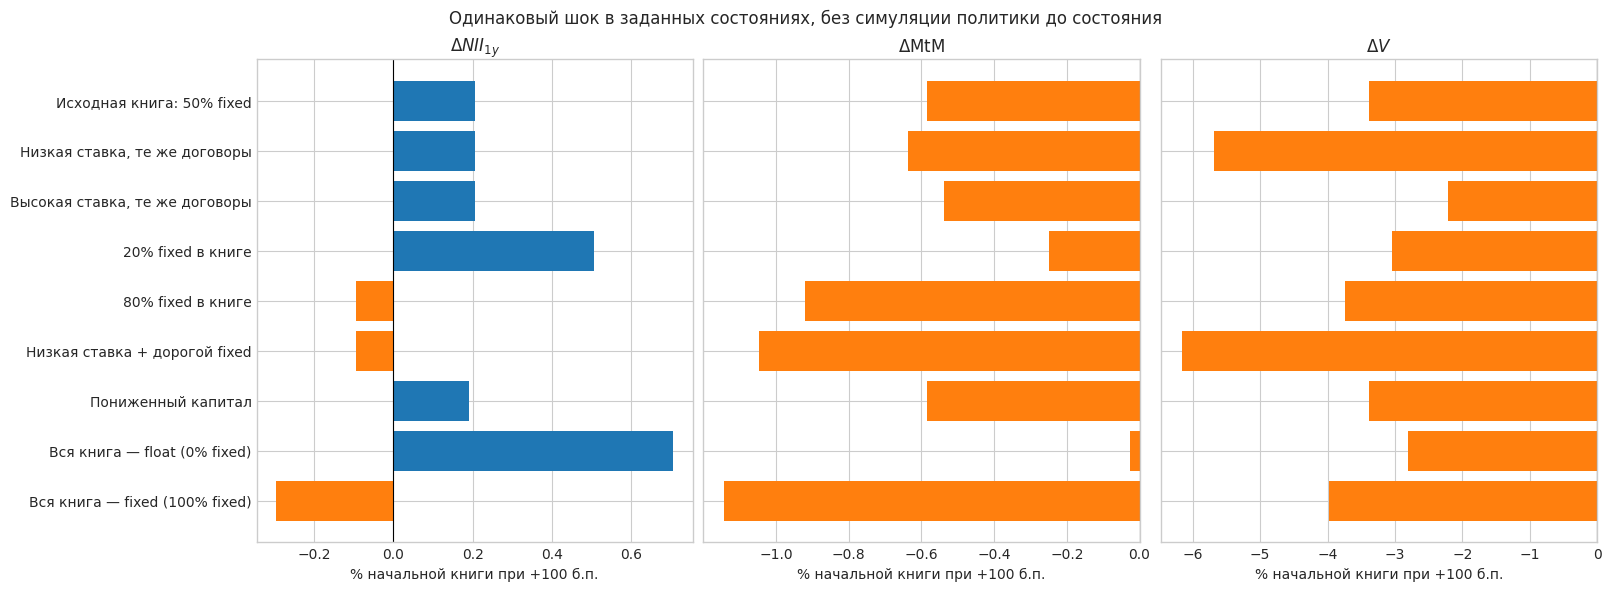

In [8]:
SCENARIO_SHOCK = 0.01
L_SC = env.loans_at(0.0)
D_SC = env.deposits_at(0.0)
r_ref, F_ref, Y_ref, E_ref = map(float, report['reference_state'])
a_ref, e_ref = F_ref/L_SC, E_ref/L_SC
old_float_spread = p.floating_spread_0 - p.floating_demand_slope*(1-a_ref)
old_fixed_coupon = ((Y_ref-old_float_spread*(L_SC-F_ref))/F_ref
                    if F_ref > 1e-8 else float(env.new_fixed_coupon(
                        torch.tensor(r_ref, device=DEVICE, dtype=dtype))))
assert old_float_spread >= 0 and old_fixed_coupon >= 0

# Каждая строка — отдельное состояние при t=0, без предшествующей симуляции.
scenario_specs = [
    (f'Исходная книга: {a_ref:.0%} fixed', r_ref, a_ref, e_ref, old_fixed_coupon),
    ('Низкая ставка, те же договоры', max(.02, r_ref-.06), a_ref, e_ref, old_fixed_coupon),
    ('Высокая ставка, те же договоры', r_ref+.06, a_ref, e_ref, old_fixed_coupon),
    ('20% fixed в книге', r_ref, .20, e_ref, old_fixed_coupon),
    ('80% fixed в книге', r_ref, .80, e_ref, old_fixed_coupon),
    ('Низкая ставка + дорогой fixed', max(.02, r_ref-.06), .80, e_ref,
     old_fixed_coupon+.02),
    ('Пониженный капитал', r_ref, a_ref, max(.105, e_ref-.02), old_fixed_coupon),
    ('Вся книга — float (0% fixed)', r_ref, .0, e_ref, old_fixed_coupon),
    ('Вся книга — fixed (100% fixed)', r_ref, 1.0, e_ref, old_fixed_coupon),
]

def make_scenario_states(specs):
    rows = []
    for _, rate, fixed_share, capital_share, fixed_coupon in specs:
        fixed = L_SC*fixed_share
        locked_income = fixed*fixed_coupon + (L_SC-fixed)*old_float_spread
        rows.append((rate, fixed, locked_income, L_SC*capital_share))
    return torch.tensor(rows, device=DEVICE, dtype=dtype)

@torch.no_grad()
def scenario_risk_metrics(x):
    """Money-unit deltas at t=0; works for either checkpoint type."""
    original_shape = x.shape[:-1]
    pieces = []
    bump = torch.tensor([SCENARIO_SHOCK, 0, 0, 0], device=DEVICE, dtype=dtype)
    for batch in x.reshape(-1, 4).split(256):
        r, F, Y, E = batch.unbind(-1)
        d_nii = SCENARIO_SHOCK*(E-F+(1-p.deposit_beta)*D_SC)
        d_mtm = (Y+p.amortization*F)*(
            env.annuity_q(r+SCENARIO_SHOCK)-env.annuity_q(r))
        d_value = solution.value(0, batch+bump)-solution.value(0, batch)
        pieces.append(torch.stack((d_nii, d_mtm, d_value), dim=-1).cpu())
    return torch.cat(pieces).reshape(*original_shape, 3).numpy()

scenario_states = make_scenario_states(scenario_specs)
scenario_deltas = scenario_risk_metrics(scenario_states)
metric_names = (r'$\Delta NII_{1y}$', r'$\Delta\mathrm{MtM}$', r'$\Delta V$')
print(f'Ставки старых договоров в исходной книге: fixed-купон={old_fixed_coupon:.2%}, '
      f'float-спред={old_float_spread:.2%}; шок=+100 б.п.')
print('Сценарий                              r    F/L    E/L    Cash/L  '
      'ΔNII_1y     ΔMtM       ΔV     (ден. ед.)')
for spec, row, delta in zip(scenario_specs, scenario_states.cpu().numpy(), scenario_deltas):
    cash_share = row[3]/L_SC + D_SC/L_SC - 1
    print(f'{spec[0]:36s} {row[0]:5.1%} {row[1]/L_SC:5.1%} '
          f'{row[3]/L_SC:5.1%} {cash_share:7.1%} '
          f'{delta[0]:+10.3f} {delta[1]:+10.3f} {delta[2]:+10.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True, constrained_layout=True)
labels = [item[0] for item in scenario_specs]
y_pos = np.arange(len(labels))
for j, ax in enumerate(axes):
    values = 100*scenario_deltas[:, j]/L_SC
    ax.barh(y_pos, values, color=np.where(values >= 0, 'tab:blue', 'tab:orange'))
    ax.axvline(0, color='black', lw=.8)
    ax.set(title=metric_names[j], xlabel='% начальной книги при +100 б.п.')
axes[0].set_yticks(y_pos, labels)
axes[0].invert_yaxis()
fig.suptitle('Одинаковый шок в заданных состояниях, без симуляции политики до состояния')
plt.show()


### Разложение шоковых метрик на денежные потоки

Для каждого заданного состояния чувствительность **замороженного** баланса к шоку $\delta=+100$ б.п. распадается на три вклада:

$$\Delta NII_{1y}=\delta\underbrace{(L-F)}_{\text{float-кредиты}}+\delta\underbrace{C}_{\text{Cash}}-\delta\underbrace{\beta D}_{\text{депозиты}},\qquad C=E+D-L.$$

Плавающие кредиты дают положительный вклад, Cash — вклад со знаком самого Cash, а повышение стоимости депозитов — отрицательный. Будущая выдача здесь не учитывается.

Для переоценки действующих договоров положим $\Delta A_Q=A_Q(r+\delta)-A_Q(r)<0$. Тогда

$$\Delta\mathrm{MtM}=\underbrace{F k_{F,\mathrm{old}}\Delta A_Q}_{\text{купоны старых fixed}}+\underbrace{(L-F)s_{V,\mathrm{old}}\Delta A_Q}_{\text{спреды старых float}}+\underbrace{\mu F\Delta A_Q}_{\text{погашение fixed-основной суммы}}.$$

В крайних сценариях старые купон и спред условно сохранены на уровне исходной книги. Цветные полосы показывают отдельные вклады; чёрный ромб — их сумму. Масштаб — проценты от начальной книги $L_0$.


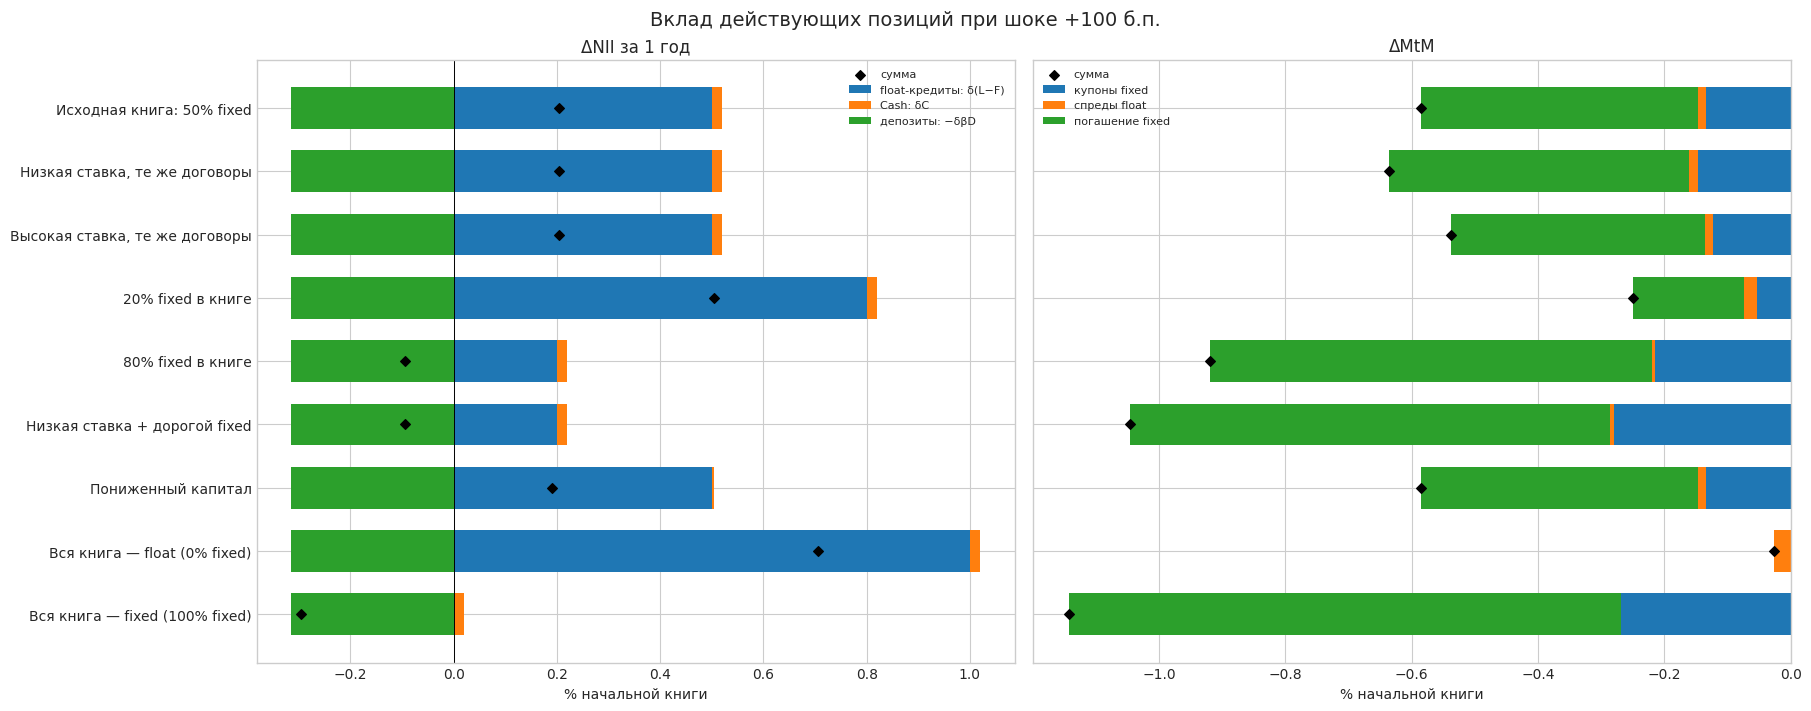

In [9]:
# Те же состояния и тот же шок, что на сценарной диаграмме выше.
with torch.no_grad():
    rates = scenario_states[:, 0]
    fixed = scenario_states[:, 1]
    cash = scenario_states[:, 3] + D_SC - L_SC
    delta_annuity = env.annuity_q(rates + SCENARIO_SHOCK) - env.annuity_q(rates)
    old_coupons = torch.tensor([spec[4] for spec in scenario_specs], device=DEVICE, dtype=dtype)
    nii_parts = torch.stack((
        SCENARIO_SHOCK*(L_SC-fixed), SCENARIO_SHOCK*cash,
        -SCENARIO_SHOCK*p.deposit_beta*torch.full_like(rates, D_SC)), -1).cpu().numpy()
    mtm_parts = torch.stack((
        fixed*old_coupons*delta_annuity,
        (L_SC-fixed)*old_float_spread*delta_annuity,
        p.amortization*fixed*delta_annuity), -1).cpu().numpy()
np.testing.assert_allclose(nii_parts.sum(1), scenario_deltas[:, 0], atol=2e-5)
np.testing.assert_allclose(mtm_parts.sum(1), scenario_deltas[:, 1], atol=2e-5)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True, constrained_layout=True)
component_sets = (
    (nii_parts, scenario_deltas[:, 0], ('float-кредиты: δ(L−F)', 'Cash: δC',
      'депозиты: −δβD'), 'ΔNII за 1 год'),
    (mtm_parts, scenario_deltas[:, 1], ('купоны fixed', 'спреды float',
      'погашение fixed'), 'ΔMtM'),
)
y_positions = np.arange(len(scenario_specs))
for ax, (parts, totals, labels, title) in zip(axes, component_sets):
    positive = np.zeros(len(parts))
    negative = np.zeros(len(parts))
    for j, (label, color) in enumerate(zip(labels, ('tab:blue','tab:orange','tab:green'))):
        values = 100*parts[:, j]/L_SC
        left = np.where(values >= 0, positive, negative)
        ax.barh(y_positions, values, left=left, color=color, label=label, height=.66)
        positive += np.maximum(values, 0)
        negative += np.minimum(values, 0)
    ax.scatter(100*totals/L_SC, y_positions, color='black', marker='D',
               s=24, zorder=4, label='сумма')
    ax.axvline(0, color='black', lw=.7)
    ax.set(xlabel='% начальной книги', title=title)
    ax.legend(fontsize=8)
axes[0].set_yticks(y_positions, [spec[0] for spec in scenario_specs])
axes[0].invert_yaxis()
fig.suptitle('Вклад действующих позиций при шоке +100 б.п.', fontsize=14)
plt.show()


## Динамика компонент риск-метрик

Предыдущие графики сравнивают вручную заданные состояния при $L=L_0$. Теперь банк начинает из первого сценария и развивается под **обученной политикой**. Из 64 случайных путей выбираются три с низкой, медианной и высокой средней ставкой за весь горизонт (ближайшие пути к 10-му, 50-му и 90-му перцентилям). Это отдельные реализации, не условные средние и не вероятностные границы.

В каждый момент $t$ текущая книга переоценивается при **новом локальном мгновенном** шоке $+100$ б.п. После вычисления метрик исходная траектория продолжается без этого диагностического шока. Поэтому линии показывают эволюцию экспозиции банка, а не накопленные потери от одного шока в начале.

1. Первый рисунок показывает ставку, размер книги, управление, накопленную долю fixed, капитал и cash на единицу книги.
2. Второй: разложения $\Delta NII_{1y}$ и $\Delta MtM$ во времени в **денежных единицах**; чёрная линия — сумма цветных вкладов. Нижняя строка сопоставляет три полных метрики, включая $\Delta V$.
3. Третий повторяет те же графики **в процентах текущей книги**, чтобы отличить рост объёма от изменения структуры.

Здесь $D_t=\nu L_t$ и $C_t=E_t+D_t-L_t$. Поэтому $-\delta\beta D_t$ изменяется в деньгах вместе с $L_t$, а $-\delta\beta D_t/L_t=-\delta\beta\nu$ постоянно. Cash может меняться и относительно книги, поскольку зависит от $E_t/L_t$.

Для разложения MtM отдельно ведём купоны fixed и спреды float: $Y_t=Y_t^F+Y_t^V$. Они стартуют из той же условной структуры старых договоров, что в сценарном анализе, и обновляются по тем же новым выдачам и амортизации. Это бухгалтерская расшифровка $Y$, дополнительной переменной управления нет. В $\Delta V$ передаётся фактический $L_t$; подстановка постоянного $L_0$ здесь была бы ошибкой. Статус сходимости исходного чекпоинта остаётся существенным для точности $\Delta V$.

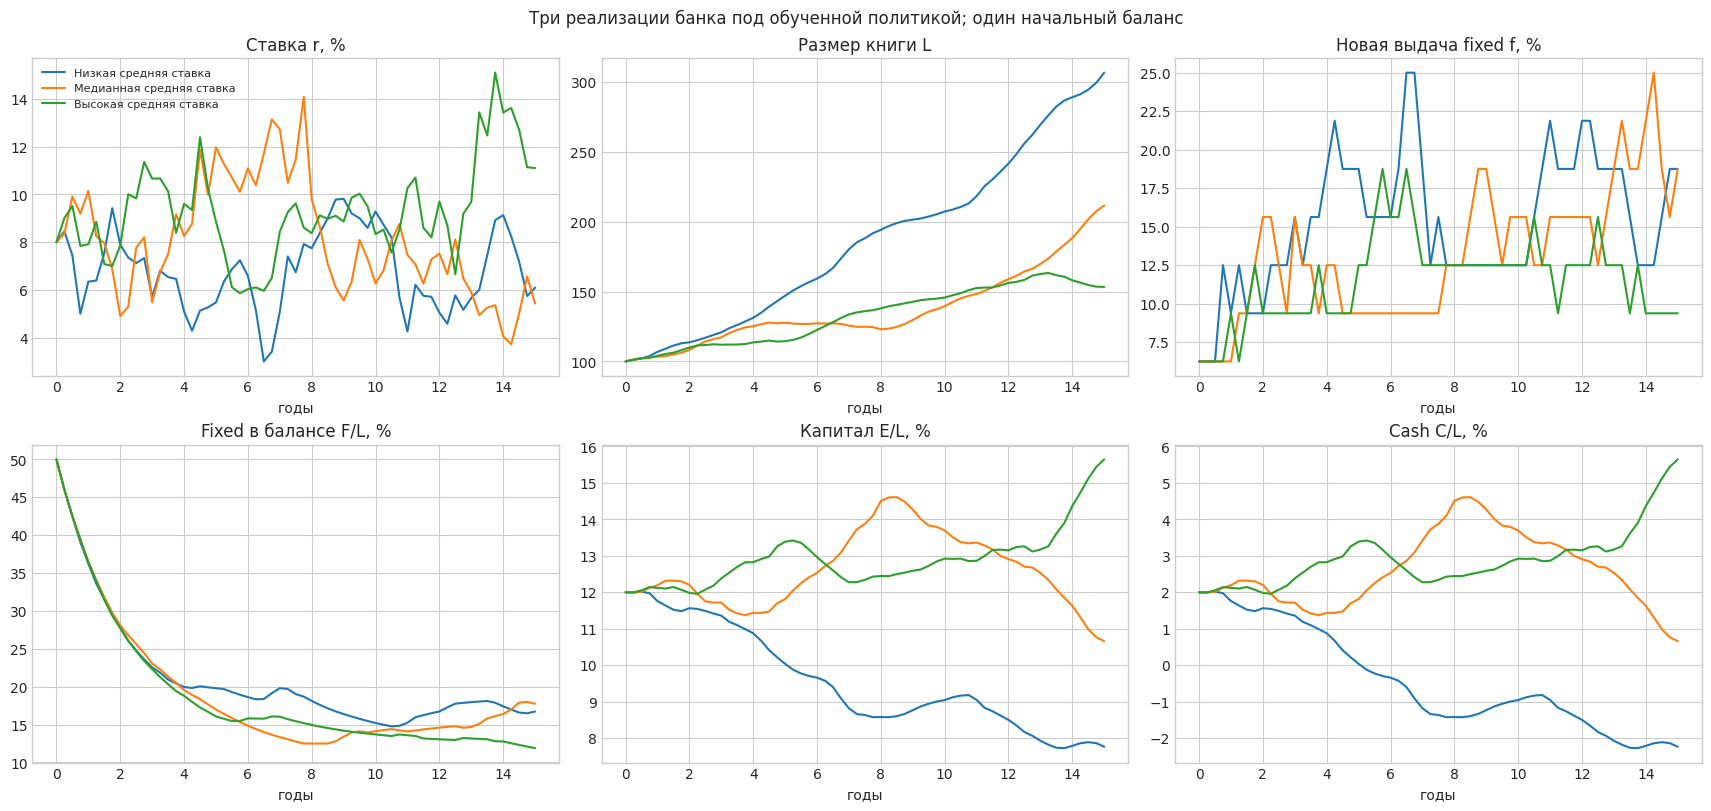

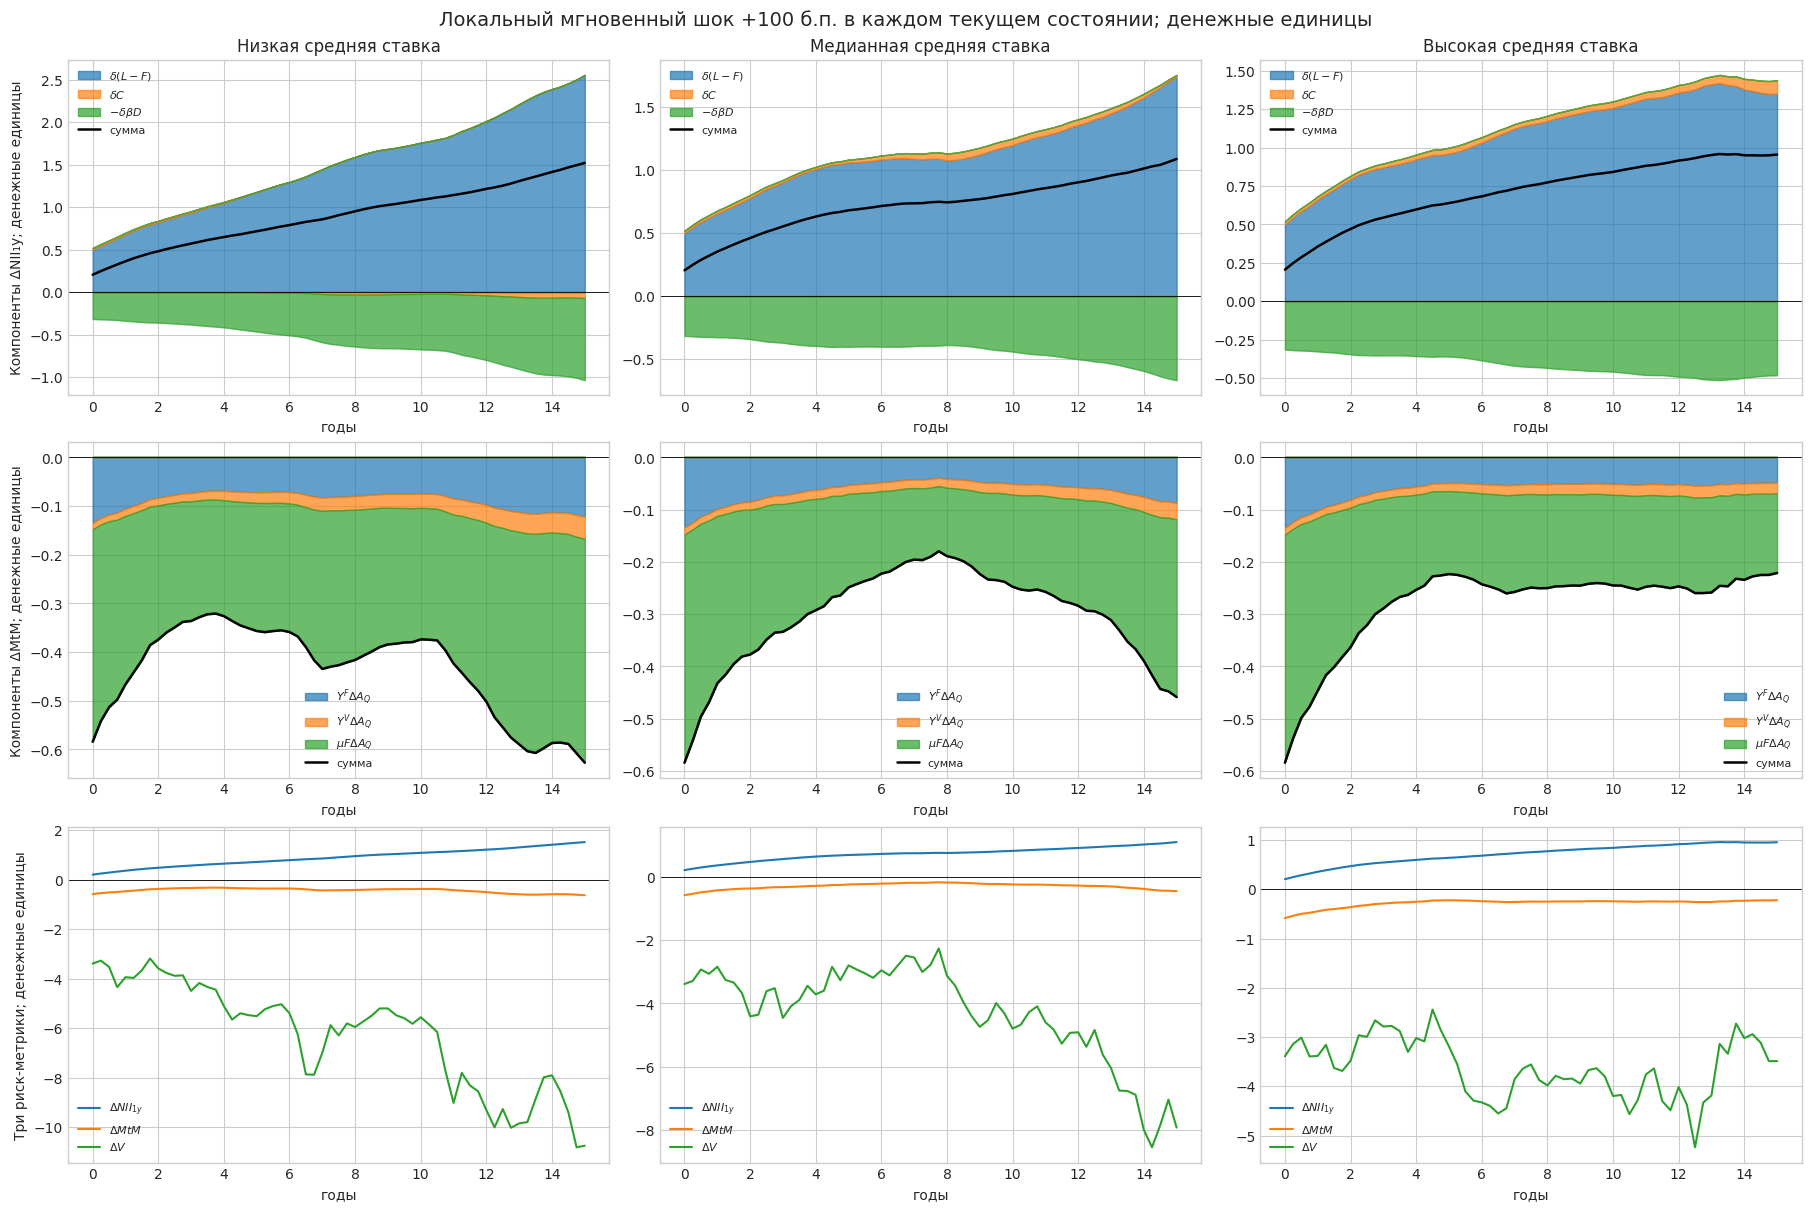

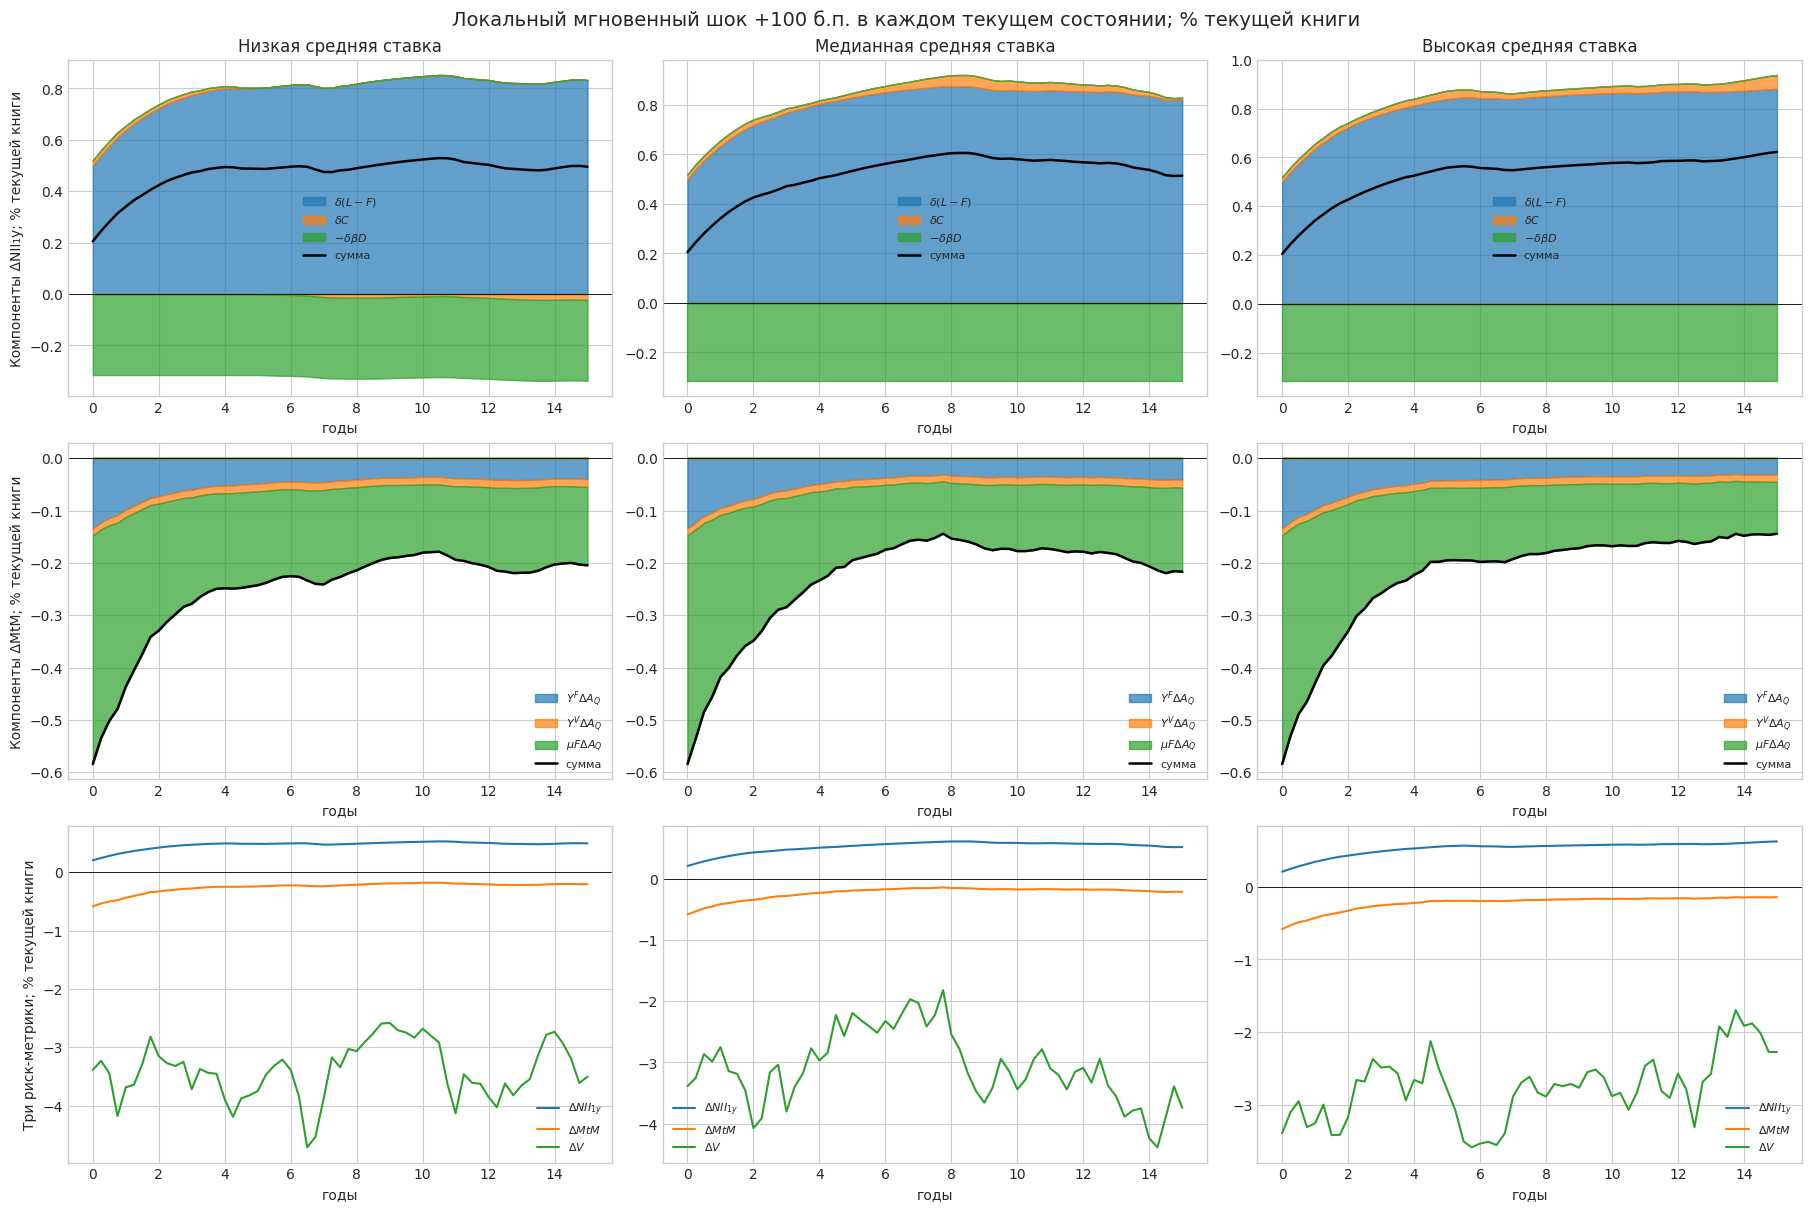

Депозитный вклад в ΔNII/L постоянен по определению D=νL; его динамика в деньгах отражает изменение L. Диагностические шоки не меняют траектории.


In [10]:
DYNAMIC_YEARS = 2.0 if SMOKE else 15.0
DYNAMIC_PATHS = 8 if SMOKE else 64
DYNAMIC_SEED = 1977
DYNAMIC_ACTIONS = cfg.action_count

@torch.no_grad()
def dynamic_risk_paths():
    steps=round(DYNAMIC_YEARS/cfg.dt)
    gen=torch.Generator(device='cpu').manual_seed(DYNAMIC_SEED)
    noise=torch.randn(steps,DYNAMIC_PATHS,generator=gen,dtype=dtype).to(DEVICE)
    x=scenario_states[0].expand(DYNAMIC_PATHS,-1).clone()
    loans=torch.full((DYNAMIC_PATHS,),float(L_SC),device=DEVICE,dtype=dtype)
    yf=x[:,1]*old_fixed_coupon
    yv=(loans-x[:,1])*old_float_spread
    history={key:[] for key in ('x','loans','action','yf','yv')}
    for k in range(steps+1):
        action=source_solution.action(x,time=k*cfg.dt,loans=loans,
                                      action_count=DYNAMIC_ACTIONS)
        for key,value in (('x',x),('loans',loans),('action',action),('yf',yf),('yv',yv)):
            history[key].append(value.clone())
        if k==steps:break
        coupon=env.new_fixed_coupon(x[:,0])
        transition=env.step(x,action,noise[k],cfg.dt,time=k*cfg.dt,
                            loans=loans,validate=False,fixed_coupon=coupon)
        decay=np.exp(-p.amortization*cfg.dt)
        new_issuance=transition.next_loans-decay*loans
        yf=decay*yf+new_issuance*action*coupon
        yv=decay*yv+new_issuance*(1-action)*env.new_floating_spread(1-action)
        x,loans=transition.state,transition.next_loans
        torch.testing.assert_close(yf+yv,x[:,2],rtol=1e-8,atol=1e-8)
    history={key:torch.stack(value) for key,value in history.items()}
    # Pick representative paths by time-averaged rate, not by policy outcome.
    integrated=(history['x'][:-1,:,0]*cfg.dt).sum(0)
    order=torch.argsort(integrated)
    ranks=torch.tensor([round(q*(DYNAMIC_PATHS-1)) for q in (.1,.5,.9)],device=DEVICE)
    chosen=order[ranks]
    selected={key:value[:,chosen] for key,value in history.items()}
    xx=selected['x'];ll=selected['loans']
    rr,ff,yy,ee=xx.unbind(-1)
    dd=(p.deposits/p.loans)*ll
    cc=ee+dd-ll
    annuity_gap=env.annuity_q(rr+SCENARIO_SHOCK)-env.annuity_q(rr)
    nii=torch.stack((SCENARIO_SHOCK*(ll-ff),SCENARIO_SHOCK*cc,
                     -SCENARIO_SHOCK*p.deposit_beta*dd),dim=-1)
    mtm=torch.stack((selected['yf']*annuity_gap,selected['yv']*annuity_gap,
                     p.amortization*ff*annuity_gap),dim=-1)
    flat_x=xx.reshape(-1,4);flat_l=ll.reshape(-1)
    bump=torch.tensor([SCENARIO_SHOCK,0,0,0],device=DEVICE,dtype=dtype)
    dvalue=torch.cat([source_solution.value(xb+bump,loans=lb)-source_solution.value(xb,loans=lb)
                      for xb,lb in zip(flat_x.split(256),flat_l.split(256))]).reshape(rr.shape)
    torch.testing.assert_close(mtm.sum(-1),(yy+p.amortization*ff)*annuity_gap)
    torch.testing.assert_close(nii.sum(-1),SCENARIO_SHOCK*(ll-ff+cc-p.deposit_beta*dd))
    selected.update(cash=cc,nii=nii,mtm=mtm,dvalue=dvalue)
    return np.arange(steps+1)*cfg.dt,{key:value.cpu().numpy() for key,value in selected.items()}

dyn_time,dyn=dynamic_risk_paths()
dyn_labels=('Низкая средняя ставка','Медианная средняя ставка','Высокая средняя ставка')
fig,dyn_axes=plt.subplots(2,3,figsize=(17,8),constrained_layout=True)
for j,label in enumerate(dyn_labels):
    rr,ff,yy,ee=dyn['x'][:,j].T
    ll=dyn['loans'][:,j]
    for ax,series,title in zip(dyn_axes.flat,
        (100*rr,ll,100*dyn['action'][:,j],100*ff/ll,100*ee/ll,100*dyn['cash'][:,j]/ll),
        ('Ставка r, %','Размер книги L','Новая выдача fixed f, %','Fixed в балансе F/L, %',
         'Капитал E/L, %','Cash C/L, %')):
        ax.plot(dyn_time,series,label=label,color=f'C{j}')
        ax.set(title=title,xlabel='годы')
dyn_axes[0,0].legend(fontsize=8)
fig.suptitle('Три реализации банка под обученной политикой; один начальный баланс')
plt.show()

def signed_component_area(ax,t,parts,labels,colors):
    positive=np.zeros(len(t));negative=np.zeros(len(t))
    for j,(label,color) in enumerate(zip(labels,colors)):
        upper=np.maximum(parts[:,j],0);lower=np.minimum(parts[:,j],0)
        ax.fill_between(t,positive,positive+upper,color=color,alpha=.7,label=label)
        ax.fill_between(t,negative,negative+lower,color=color,alpha=.7)
        positive+=upper;negative+=lower
    ax.plot(t,parts.sum(-1),color='black',lw=1.8,label='сумма')
    ax.axhline(0,color='black',lw=.6)

for dyn_normalize in (False,True):
    fig,axes=plt.subplots(3,3,figsize=(18,12),constrained_layout=True)
    for j,label in enumerate(dyn_labels):
        scale=100/dyn['loans'][:,j] if dyn_normalize else np.ones(len(dyn_time))
        signed_component_area(axes[0,j],dyn_time,dyn['nii'][:,j]*scale[:,None],
            (r'$\delta(L-F)$',r'$\delta C$',r'$-\delta\beta D$'),
            ('tab:blue','tab:orange','tab:green'))
        signed_component_area(axes[1,j],dyn_time,dyn['mtm'][:,j]*scale[:,None],
            (r'$Y^F\Delta A_Q$',r'$Y^V\Delta A_Q$',r'$\mu F\Delta A_Q$'),
            ('tab:blue','tab:orange','tab:green'))
        axes[0,j].set_title(label)
        for values,name,color in ((dyn['nii'][:,j].sum(-1),r'$\Delta NII_{1y}$','C0'),
                                  (dyn['mtm'][:,j].sum(-1),r'$\Delta MtM$','C1'),
                                  (dyn['dvalue'][:,j],r'$\Delta V$','C2')):
            axes[2,j].plot(dyn_time,values*scale,label=name,color=color)
        axes[2,j].axhline(0,color='black',lw=.6)
        for ax in axes[:,j]:
            ax.set_xlabel('годы');ax.legend(fontsize=8)
    units='% текущей книги' if dyn_normalize else 'денежные единицы'
    for ax,label in zip(axes[:,0],('Компоненты ΔNII₁y','Компоненты ΔMtM','Три риск-метрики')):
        ax.set_ylabel(label+'; '+units)
    fig.suptitle('Локальный мгновенный шок +100 б.п. в каждом текущем состоянии; '+units,fontsize=14)
    plt.show()
print('Депозитный вклад в ΔNII/L постоянен по определению D=νL; '
      'его динамика в деньгах отражает изменение L. Диагностические шоки не меняют траектории.')

### Ставка, политика и финансирование растущей книги

Во временных графиках одновременно меняются ставка и баланс. Поэтому ниже к траекториям $r_t,f_t$ добавлен **контролируемый срез**: варьируем только текущую ставку, фиксируя $F,Y,E,L$. Для этой модели обратная зависимость заметна в обычном диапазоне, но не является строгой глобальной монотонностью: на высоких ставках возможен разворот. Ступени соответствуют сетке действий, а не дискретному правилу выдачи в экономике.

Fixed-купон равен $k_F(r)=A_Q(r)^{-1}-\mu+s_F$. Возврат ставки к среднему уже учтён в par-купонной части $A_Q^{-1}-\mu$. Поэтому стратегия «зафиксировать высокий купон, пока ставка высокая» не даёт автоматического дополнительного дохода: этот купон сравнивается со всей будущей траекторией float и фондирования. В текущей калибровке при $r=2\%$ новый fixed-купон около 6.82%, а при $r=18\%$ — около 14.14%, ниже текущей базовой float-ставки. Это сравнение текущих купонов иллюстрирует carry, но само по себе не доказывает оптимальность: политика учитывает будущие потоки, риск, цену float-спреда и состав старой книги.

Отрицательный cash — разрешённая моделью **чистая заёмная денежная позиция**, а не исчезновение денег. $C/L=E/L+\nu-1$, поэтому при $\nu=0.9$ cash отрицателен ровно при $E/L<10\%$. Тогда дополнительное фондирование $B=(-C)^+$ стоит $r+s_B$. На отдельном рисунке показаны положительный cash и дополнительный долг как две неотрицательные величины.

Причина размывания капитала при низкой ставке видна из
$$\frac{d(E/L)}{dt}=(1-\alpha)\frac{\Pi}{L}-g(r)\frac{E}{L}.$$
При $\alpha=0.9$ капитал получает только 10% прибыли, а низкая ставка ускоряет экзогенный рост книги через $\chi=5$. Новые кредиты и соответствующие депозиты растут быстрее капитала. Если такой режим нежелателен, нужно менять правило роста/выплат либо ограничивать дополнительное фондирование; обнуление отрицательного $C$ без изменения баланса нарушило бы учёт.

Формально в непрерывной HJB для $v=V/L$, $a=F/L$, $y=Y/L$ действие входит как $(\mu+g)[fv_a+\{fk_F+(1-f)s_V(1-f)\}v_y]$ с точностью до постоянных по $f$ членов. Поэтому предельная выгода fixed пропорциональна
$$v_a+\{k_F(r)-s_V^0+2\eta(1-f)\}v_y.$$
Один лишь рост $k_F$ действительно усиливает стимул fixed; обратное движение политики означает, что меняющаяся предельная стоимость состава книги перевешивает этот канал. Нельзя объяснить весь результат только сравнением сегодняшних купонов. Численная политика получена конечным Bellman-шагом, а не непосредственным решением этой HJB.


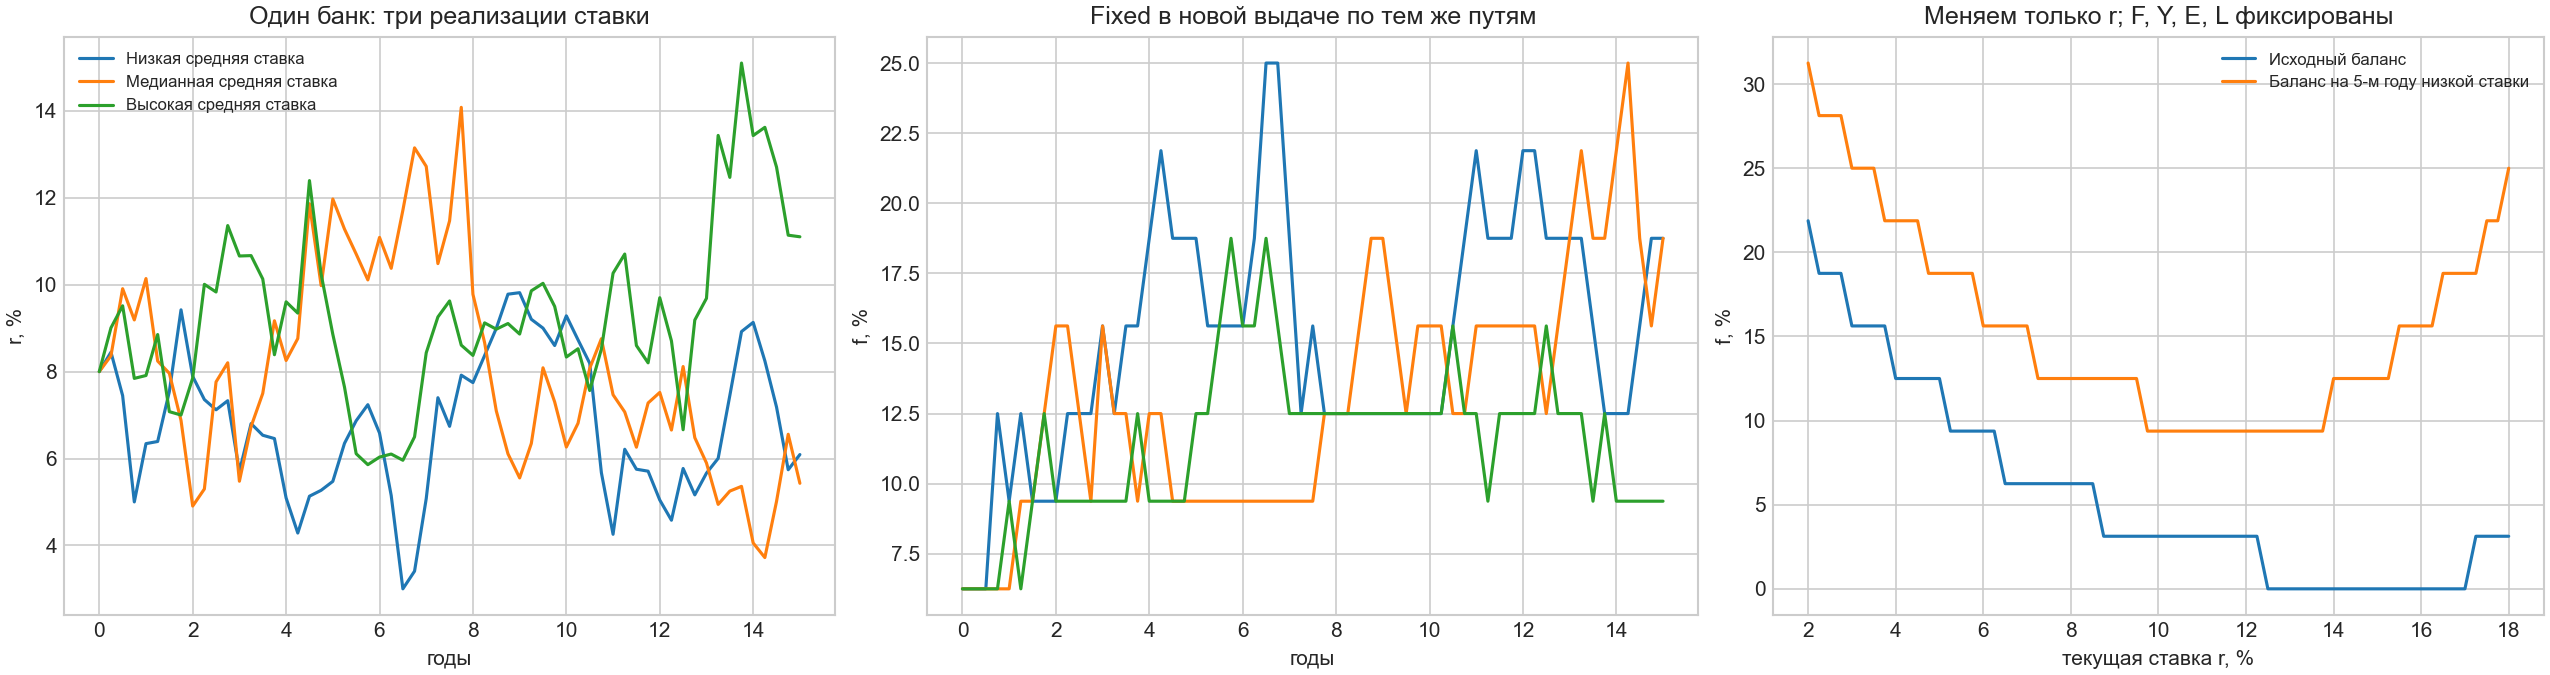

Низкая средняя ставка: L(T)=306.66, E(T)=23.82, E/L=7.77%, C/L=-2.23%; первое C<0: 5.25
Медианная средняя ставка: L(T)=211.60, E(T)=22.56, E/L=10.66%, C/L=0.66%; первое C<0: нет
Высокая средняя ставка: L(T)=153.32, E(T)=23.98, E/L=15.64%, C/L=5.64%; первое C<0: нет


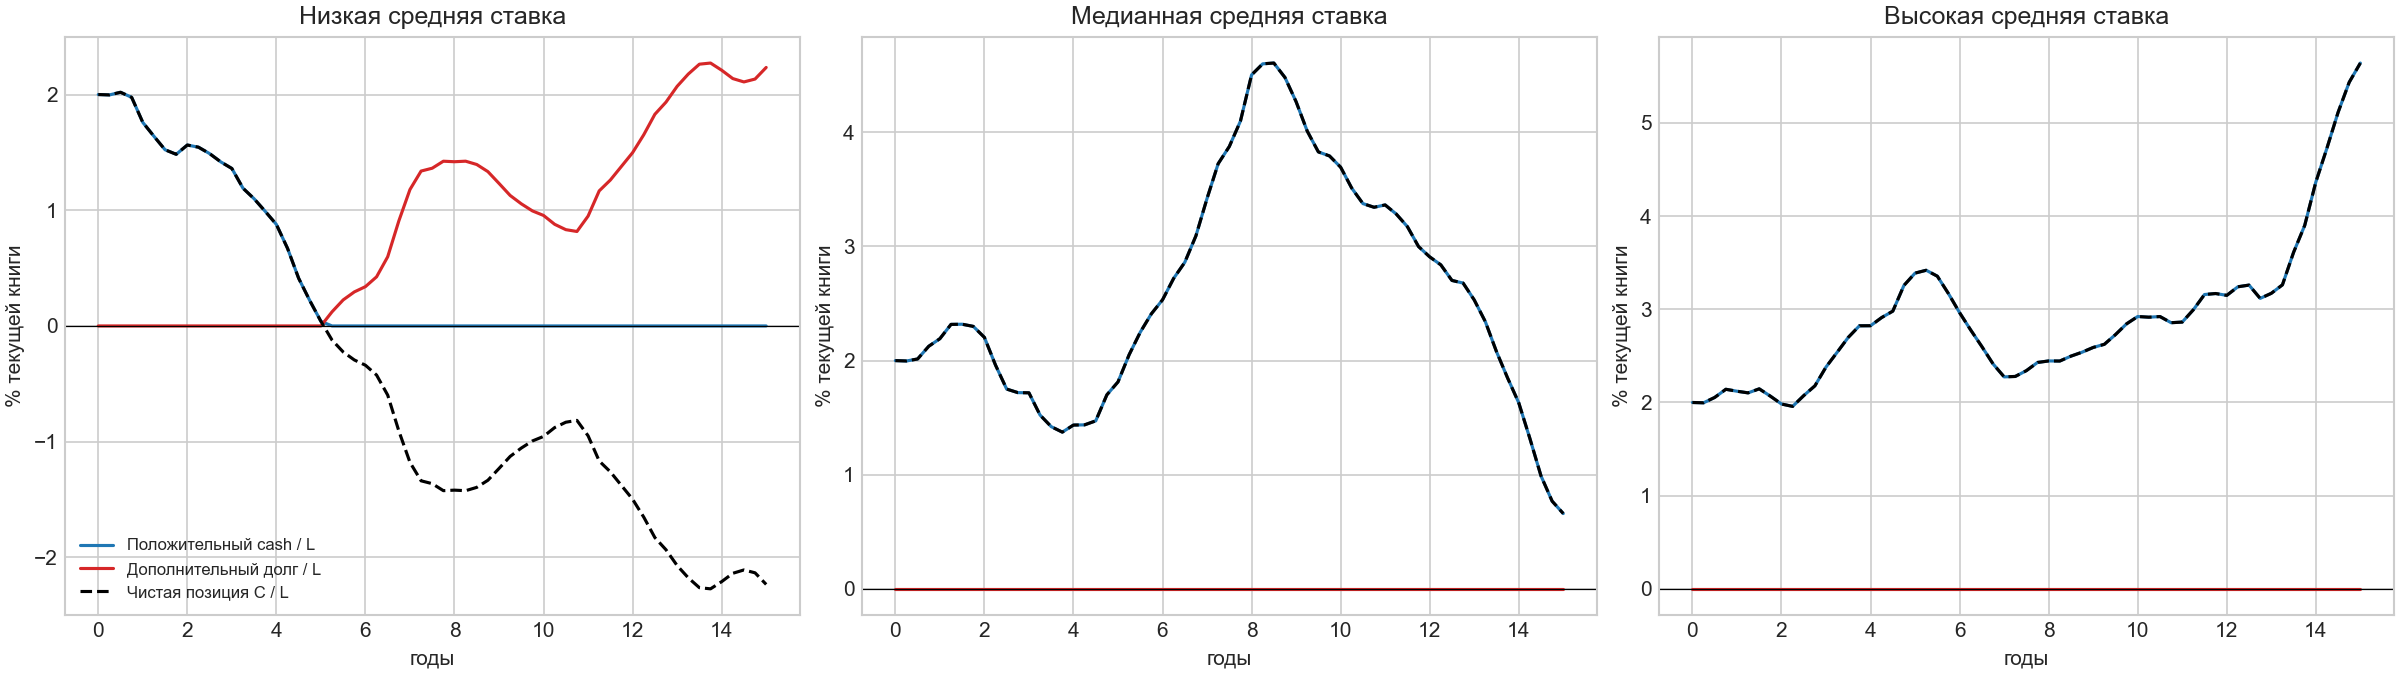

r, %: [ 2.  8. 14. 18.]
новый fixed-купон, %: [ 6.82221152  9.46076459 12.22481243 14.13773908]


In [ ]:
fig,pol_axes=plt.subplots(1,3,figsize=(17,4.5),constrained_layout=True)
for j,label in enumerate(dyn_labels):
    pol_axes[0].plot(dyn_time,100*dyn['x'][:,j,0],label=label,color=f'C{j}')
    pol_axes[1].plot(dyn_time,100*dyn['action'][:,j],color=f'C{j}')
rate_grid=torch.linspace(.02,.18,65,device=DEVICE,dtype=dtype)
slice_index=min(int(round(5/cfg.dt)),len(dyn_time)-1)
for index,path,label in ((0,0,'Исходный баланс'),
                         (slice_index,0,f'Баланс на {dyn_time[slice_index]:g}-м году низкой ставки')):
    state=torch.as_tensor(dyn['x'][index,path],device=DEVICE,dtype=dtype).expand(len(rate_grid),-1).clone()
    state[:,0]=rate_grid
    book=torch.full((len(rate_grid),),float(dyn['loans'][index,path]),device=DEVICE,dtype=dtype)
    with torch.no_grad():action=source_solution.action(state,loans=book,action_count=cfg.action_count)
    pol_axes[2].plot(100*rate_grid.cpu().numpy(),100*action.cpu().numpy(),label=label)
pol_axes[0].set(title='Один банк: три реализации ставки',xlabel='годы',ylabel='r, %')
pol_axes[1].set(title='Fixed в новой выдаче по тем же путям',xlabel='годы',ylabel='f, %')
pol_axes[2].set(title='Меняем только r; F, Y, E, L фиксированы',xlabel='текущая ставка r, %',ylabel='f, %')
pol_axes[0].legend(fontsize=8);pol_axes[2].legend(fontsize=8)
plt.show()

fig,fin_axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for j,(ax,label) in enumerate(zip(fin_axes,dyn_labels)):
    c=100*dyn['cash'][:,j]/dyn['loans'][:,j]
    ax.plot(dyn_time,np.maximum(c,0),label='Положительный cash / L',color='tab:blue')
    ax.plot(dyn_time,np.maximum(-c,0),label='Дополнительный долг / L',color='tab:red')
    ax.plot(dyn_time,c,label='Чистая позиция C / L',color='black',ls='--')
    ax.axhline(0,color='black',lw=.6)
    ax.set(title=label,xlabel='годы',ylabel='% текущей книги')
    L=dyn['loans'][-1,j];E=dyn['x'][-1,j,3]
    crossing=np.flatnonzero(c<0)
    first=f'{dyn_time[crossing[0]]:g}' if len(crossing) else 'нет'
    print(f'{label}: L(T)={L:.2f}, E(T)={E:.2f}, E/L={100*E/L:.2f}%, '
          f'C/L={c[-1]:.2f}%; первое C<0: {first}')
fin_axes[0].legend(fontsize=8)
plt.show()
with torch.no_grad():
    rates=torch.tensor([.02,.08,.14,.18],device=DEVICE,dtype=dtype)
    print('r, %:',(100*rates).cpu().numpy())
    print('новый fixed-купон, %:',(100*env.new_fixed_coupon(rates)).cpu().numpy())

## Перманентный шок: текущая ставка и долгосрочное среднее

Сравниваем два шока $\delta=100$ б.п. при одинаковом начальном балансе $(L,F,Y,E)$:

* мгновенный: $r\mapsto r+\delta$, параметры динамики и оценки прежние;
* перманентный: $r\mapsto r+\delta$, $\bar r_P\mapsto\bar r_P+\delta$ и $\bar r_Q\mapsto\bar r_Q+\delta$.

Под CIR разрыв **ожидаемых** ставок в первом случае убывает как $\delta e^{-\kappa_P t}$, во втором равен $\delta$ на всём горизонте. Это не точный сдвиг каждого случайного пути или каждой точки доходности: волатильность CIR зависит от уровня ставки.

Старые договоры $F,Y$ при шоке не меняются. Новые fixed-купоны рассчитываются по изменённой кривой $Q$; стоимость депозитов и рост книги продолжают зависеть от абсолютной ставки. Опорная ставка спроса $r_0$ и прочие параметры **не сдвигаются**. Поэтому этот опыт включает устойчивое изменение объёма будущей выдачи.

Для $\Delta V$ нужны две задачи управления. Ячейка ниже продолжает обучение базовой среды и среды со сдвинутыми средними из одного исходного чекпоинта, с одинаковыми настройками и seed. Максимум по управлению сохраняется: это переоптимизация, а не оценка замороженной политики. Готовые решения загружаются из отдельного кеша. Новый расчёт может быть долгим; рекомендуем GPU. Этот раздел не использует кеш полногоризонтных оценок политик из следующих разделов.

In [11]:
from dataclasses import asdict
from continuous_time_irrbb.risk_sensitive.environment import Environment
from continuous_time_irrbb.risk_sensitive.stationary_solver import solve_stationary

PERMANENT_SHIFT = SCENARIO_SHOCK
PERMANENT_TRAIN_IF_MISSING = False  # False: только загрузить готовые решения
PERMANENT_ITERATIONS = 2 if SMOKE else 1000
PERMANENT_TOLERANCE = .005
permanent_config = replace(
    cfg, iterations=PERMANENT_ITERATIONS, residual_tolerance=PERMANENT_TOLERANCE,
    learning_rate=min(cfg.learning_rate,.0005),
    train_states=64 if SMOKE else cfg.train_states,
    validation_states=32 if SMOKE else cfg.validation_states,
    epochs_per_iteration=2 if SMOKE else cfg.epochs_per_iteration,
    exploration_steps=2 if SMOKE else cfg.exploration_steps)
permanent_parameters = replace(p, mean_rate_p=p.mean_rate_p+PERMANENT_SHIFT,
                                mean_rate_q=p.mean_rate_q+PERMANENT_SHIFT)
permanent_settings = {
    'version':1, 'checkpoint_sha256':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
    'base_parameters':asdict(p), 'shifted_parameters':asdict(permanent_parameters),
    'config':asdict(permanent_config), 'dtype':str(dtype)}
permanent_key=hashlib.sha256(json.dumps(permanent_settings,sort_keys=True).encode()).hexdigest()[:16]
permanent_cache=(Path('/private/tmp/irrbb_permanent_smoke') if SMOKE
                 else run_dir/'permanent_shock_cache')/permanent_key
permanent_results={}
for regime,parameters in (('base',p),('permanent',permanent_parameters)):
    folder=permanent_cache/regime
    model_path=folder/'stationary_solution.pt'
    report_path=folder/'report.json'
    if model_path.exists() and report_path.exists():
        fitted=StationarySolution.load(model_path,device=DEVICE,dtype=dtype)
        info=json.loads(report_path.read_text())
        print('кеш перманентного опыта:',regime,folder)
    else:
        if not PERMANENT_TRAIN_IF_MISSING:
            raise FileNotFoundError(f'Нет {model_path}; установите PERMANENT_TRAIN_IF_MISSING=True')
        torch.manual_seed(permanent_config.seed)
        new_environment=Environment(parameters).to(device=DEVICE,dtype=dtype)
        def progress(q):
            if q['iteration']==1 or q['iteration']%50==0:
                print(f"{regime}: iter={q['iteration']}, RMSE={q['bellman_rmse']:.5f}, "
                      f"q95={q['bellman_q95_abs']:.5f}",flush=True)
        fitted,diagnostics,converged=solve_stationary(
            new_environment,permanent_config,device=torch.device(DEVICE),dtype=dtype,
            initial_net=source_solution.value_net,progress=progress)
        folder.mkdir(parents=True,exist_ok=True)
        fitted.save(model_path,diagnostics)
        info={'regime':regime,'converged':converged,'diagnostics':diagnostics,
              'settings':permanent_settings}
        report_path.write_text(json.dumps(info,ensure_ascii=False,indent=2))
    permanent_results[regime]=(fitted,info)
    last=info['diagnostics'][-1]
    print(f"{regime}: converged={info['converged']}, "
          f"RMSE={last['bellman_rmse']:.5f}, q95={last['bellman_q95_abs']:.5f}")

кеш перманентного опыта: base /home/jovyan/belyakov/ir_risk/continuous_time_irrbb/risk_sensitive/runs/stationary_rate_growth_refined/permanent_shock_cache/15a0c712d0d5583d/base
base: converged=False, RMSE=0.00716, q95=0.01283
кеш перманентного опыта: permanent /home/jovyan/belyakov/ir_risk/continuous_time_irrbb/risk_sensitive/runs/stationary_rate_growth_refined/permanent_shock_cache/15a0c712d0d5583d/permanent
permanent: converged=False, RMSE=0.00746, q95=0.01171


### Формулы трёх метрик при перманентном шоке

Пусть $A_Q(r;\bar r_Q)$ явно указывает долгосрочное среднее оценочной ставки. При неизменных $L,F,Y,E$:

$$\Delta NII_{1y}^{\rm perm}=\delta[(L-F)+C-\beta D]\cdot1\text{ год}=\Delta NII_{1y}^{\rm instant},$$

$$\Delta MtM^{\rm perm}=(Y+\mu F)\{A_Q(r+\delta;\bar r_Q+\delta)-A_Q(r;\bar r_Q)\},$$

$$\Delta V^{\rm perm}=V_{\bar r_P+\delta,\bar r_Q+\delta}(L,r+\delta,F,Y,E)-V_{\bar r_P,\bar r_Q}(L,r,F,Y,E).$$

Замороженный годовой NII не использует динамику ставки, поэтому повышение среднего его не меняет. Для MtM интегрируются все будущие платежи по изменённой кривой $Q$. Для $V$ изменяются физическая динамика ставки и цены новых кредитов; управление в каждой среде оптимизируется заново.

Ниже мгновенная $\Delta V$ тоже считается через уточнённое базовое решение, чтобы у обоих шоков был один знаменатель и одна базовая сеть. В таблице отдельно показан дрейф базового уровня относительно исходного чекпоинта. Изменение порядка обучения не гарантирует одинаковой численной ошибки; при `converged=False` это диагностическое сравнение.

Сценарий                            ΔNII (оба)  MtM instant  MtM perm   V instant   V perm   дрейф V0
Исходная книга: 50% fixed               +0.2050     -0.5844    -1.2712    -3.3915   -13.7521    -0.0777
Низкая ставка, те же договоры           +0.2050     -0.6360    -1.3975    -5.6790   -21.1514    -0.0963
Высокая ставка, те же договоры          +0.2050     -0.5374    -1.1571    -2.2299    -9.6880    -0.1007
20% fixed в книге                       +0.5050     -0.2495    -0.5427    -3.0491   -13.2852    -0.0722
80% fixed в книге                       -0.0950     -0.9193    -1.9997    -3.7384   -14.2378    -0.0814
Низкая ставка + дорогой fixed           -0.0950     -1.0462    -2.2987    -6.1474   -21.8378    -0.0735
Пониженный капитал                      +0.1900     -0.5844    -1.2712    -3.3912   -13.7189    -0.0629
Вся книга — float (0% fixed)            +0.7050     -0.0262    -0.0570    -2.8251   -12.9568    -0.0512
Вся книга — fixed (100% fixed)          -0.2950     -1.1426    -2.

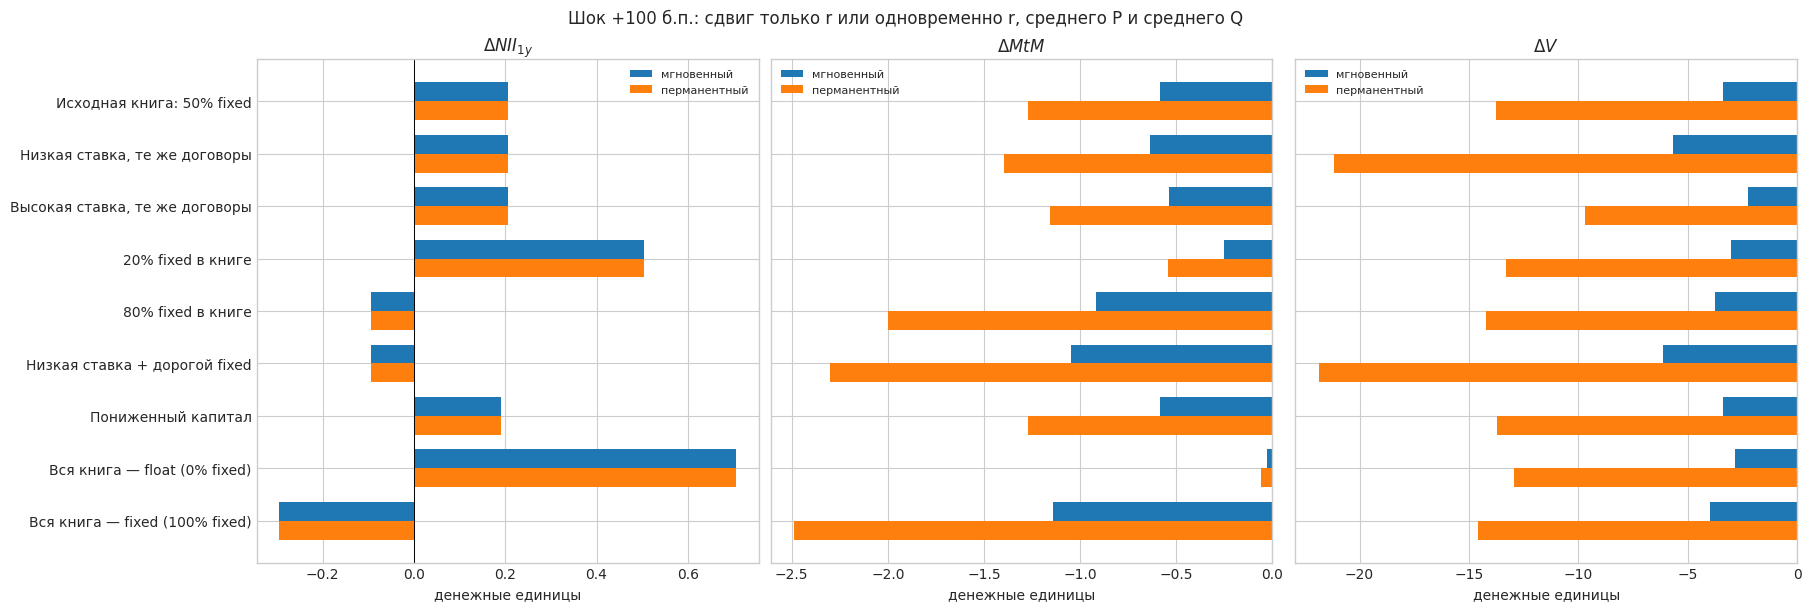

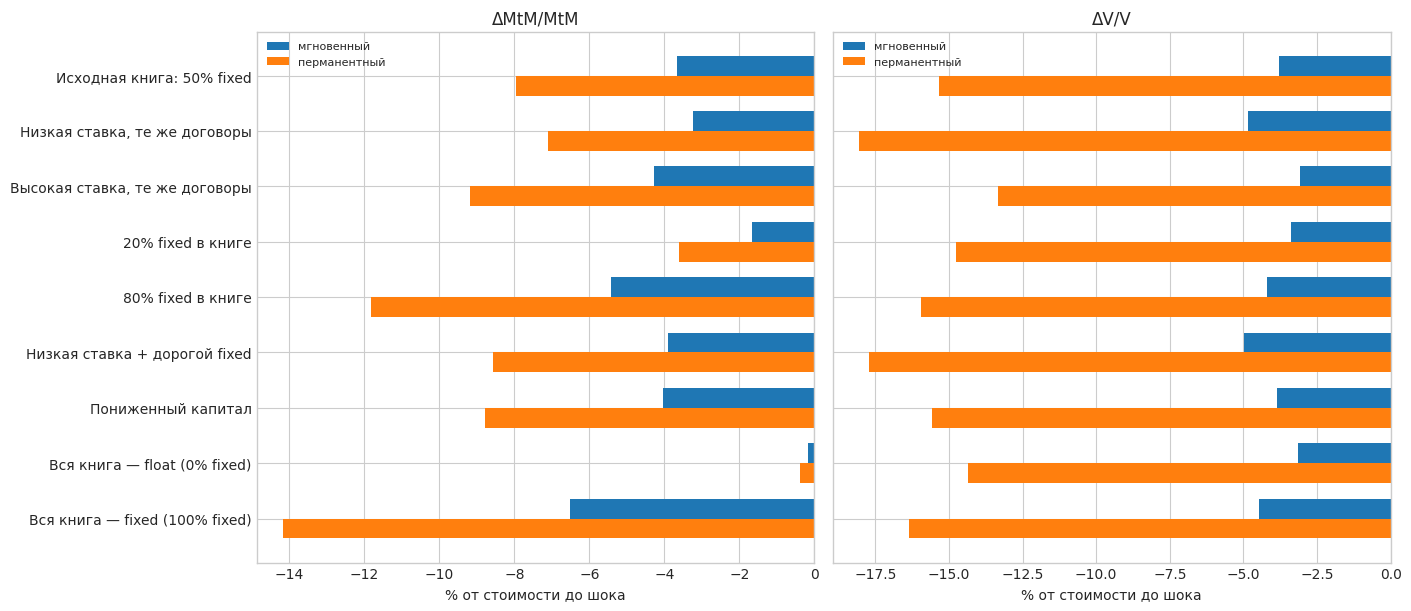

ВНИМАНИЕ: хотя бы одна задача не сошлась. ΔV и её различия предварительны; смотрите невязки и дрейф базового уровня. Аналитические NII и MtM от обучения не зависят.


In [12]:
base_permanent,base_permanent_report=permanent_results['base']
shifted_permanent,shifted_permanent_report=permanent_results['permanent']
with torch.no_grad():
    shock_vector=torch.tensor([PERMANENT_SHIFT,0,0,0],device=DEVICE,dtype=dtype)
    x0=scenario_states
    x1=x0+shock_vector
    rr,ff,yy,ee=x0.unbind(-1)
    cc=ee+D_SC-L_SC
    nii=PERMANENT_SHIFT*(L_SC-ff+cc-p.deposit_beta*D_SC)
    mtm0=env.terminal_value(x0)
    mtm_instant=(yy+p.amortization*ff)*(env.annuity_q(rr+PERMANENT_SHIFT)-env.annuity_q(rr))
    mtm_permanent=(yy+p.amortization*ff)*(
        shifted_permanent.environment.annuity_q(rr+PERMANENT_SHIFT)-env.annuity_q(rr))
    vb=base_permanent.value(x0)
    vi=base_permanent.value(x1)
    vp=shifted_permanent.value(x1)
    source_base=source_solution.value(x0)
    instant=np.column_stack((nii.cpu(),mtm_instant.cpu(),(vi-vb).cpu()))
    permanent=np.column_stack((nii.cpu(),mtm_permanent.cpu(),(vp-vb).cpu()))
    base_drift=(vb-source_base).cpu().numpy()
    vb_array=vb.cpu().numpy()
    mtm0_array=mtm0.cpu().numpy()
labels=[row[0] for row in scenario_specs]
print('Сценарий                            ΔNII (оба)  MtM instant  MtM perm   V instant   V perm   дрейф V0')
for i,label in enumerate(labels):
    print(f'{label:36s} {instant[i,0]:+10.4f} {instant[i,1]:+11.4f} '
          f'{permanent[i,1]:+10.4f} {instant[i,2]:+10.4f} {permanent[i,2]:+10.4f} '
          f'{base_drift[i]:+10.4f}')
fig,axes=plt.subplots(1,3,figsize=(18,6),sharey=True,constrained_layout=True)
y=np.arange(len(labels)); h=.36
for j,(ax,name) in enumerate(zip(axes,(r'$\Delta NII_{1y}$',r'$\Delta MtM$',r'$\Delta V$'))):
    ax.barh(y-h/2,instant[:,j],h,label='мгновенный',color='tab:blue')
    ax.barh(y+h/2,permanent[:,j],h,label='перманентный',color='tab:orange')
    ax.set(title=name,xlabel='денежные единицы',yticks=y,yticklabels=labels)
    ax.axvline(0,color='black',lw=.7);ax.legend(fontsize=8)
axes[0].invert_yaxis()
fig.suptitle('Шок +100 б.п.: сдвиг только r или одновременно r, среднего P и среднего Q')
plt.show()

# Relative sensitivities share the same unshocked denominator for the two regimes.
fig,axes=plt.subplots(1,2,figsize=(14,6),sharey=True,constrained_layout=True)
for ax,column,denominator,name in ((axes[0],1,mtm0_array,'MtM'),(axes[1],2,vb_array,'V')):
    for values,offset,label,color in ((instant,-h/2,'мгновенный','tab:blue'),
                                      (permanent,h/2,'перманентный','tab:orange')):
        rel=np.divide(100*values[:,column],denominator,
                      out=np.full_like(denominator,np.nan),where=denominator>.01*L_SC)
        ax.barh(y+offset,rel,h,label=label,color=color)
    ax.set(title=f'Δ{name}/{name}',xlabel='% от стоимости до шока',yticks=y,yticklabels=labels)
    ax.axvline(0,color='black',lw=.7);ax.legend(fontsize=8)
axes[0].invert_yaxis();plt.show()
if not (base_permanent_report['converged'] and shifted_permanent_report['converged']):
    print('ВНИМАНИЕ: хотя бы одна задача не сошлась. ΔV и её различия предварительны; '
          'смотрите невязки и дрейф базового уровня. Аналитические NII и MtM от обучения не зависят.')

## Парные траектории: рост книги, выдача и дисконтирование

Чтобы увидеть механизм большого различия между $\Delta MtM$ и $\Delta V$, запускаем две ветви из **одного исходного состояния**, во второй сразу повышаем ставку на 100 б.п. Они получают одинаковые случайные приращения. В обеих ветвях доля новых fixed-кредитов постоянно равна 50%: так изменение объёма выдач нельзя спутать с адаптацией политики. Старый MtM не учитывает ни будущую выдачу, ни будущий рост книги.

На каждом шаге численной схемы дисконтированный поток владельцу записывается **точно** как $D_k L_{k+1/2}m_k$, где $D_k$ включает накопленный и внутришаговый дисконт, $L_{k+1/2}$ — размер книги в середине шага, $m_k=\alpha p_k\,\Delta t$ — поток на единицу книги. Поэтому парная разница потока раскладывается без остатка:

$$\Delta(DLm)=(D^+-D)Lm+D^+(L^+-L)m+D^+L^+(m^+-m).$$

Три члена справа показывают **дисконтирование**, **масштаб книги** и **прибыль на единицу книги** (в последнем также есть влияние ставки, структуры договоров и cash). Разделение зависит от порядка подстановки контрфактов; суммарная разница — нет. Это иллюстрация потоков на конечном горизонте при фиксированной стратегии, **не точное разложение бессрочной риск-чувствительной** $\Delta V$. Невыплаченный к концу показанного горизонта капитал и потоки после него сюда не включены.

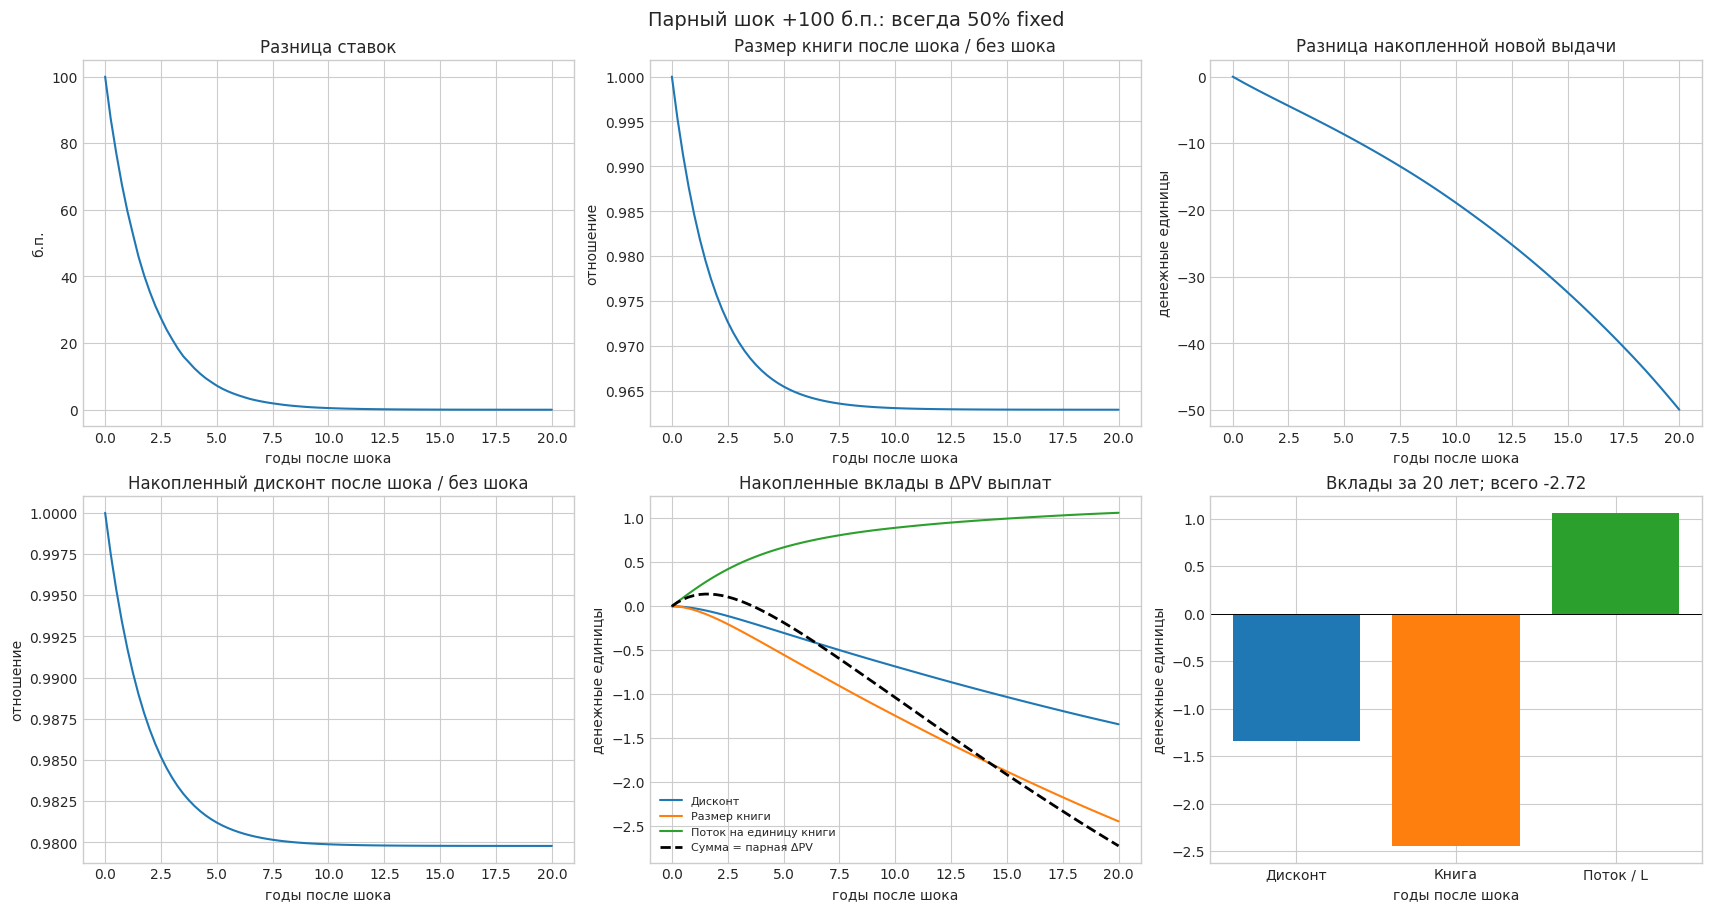

Парный шок +100 б.п.: всегда 50% fixed; горизонт 20 лет: средняя парная ΔPV потоков -2.7229; дисконт -1.3406, размер книги -2.4440, поток на единицу книги +1.0616.
Это обрезанная риск-нейтральная стоимость потока, не бессрочная риск-чувствительная ΔV.


In [13]:
MECH_YEARS = 5.0 if SMOKE else 20.0
MECH_PATHS = 32 if SMOKE else 256
MECH_SEED = 2407
mech_dt = cfg.dt
mech_steps = round(MECH_YEARS/mech_dt)

@torch.no_grad()
def paired_mechanisms(policy):
    generator=torch.Generator(device='cpu').manual_seed(MECH_SEED)
    noises=torch.randn(mech_steps,MECH_PATHS,generator=generator,dtype=dtype).to(DEVICE)
    base=scenario_states[0].expand(MECH_PATHS,-1).clone()
    shock=base.clone()
    shock[:,0]+=SCENARIO_SHOCK
    state=torch.cat((base,shock),0)
    loans=torch.full((2*MECH_PATHS,),float(L_SC),device=DEVICE,dtype=dtype)
    discount=torch.ones_like(loans)
    gross_issued=torch.zeros_like(loans)
    times=[0.]
    rates=[state[:,0].reshape(2,MECH_PATHS).cpu().numpy().copy()]
    books=[loans.reshape(2,MECH_PATHS).cpu().numpy().copy()]
    discounts=[discount.reshape(2,MECH_PATHS).cpu().numpy().copy()]
    issues=[gross_issued.reshape(2,MECH_PATHS).cpu().numpy().copy()]
    contribution=[]
    flow_gap=[]
    for k in range(mech_steps):
        if policy=='half':
            actions=torch.full((2*MECH_PATHS,),BASELINE_FIXED_SHARE,
                               device=DEVICE,dtype=dtype)
        elif policy=='learned':
            actions=source_solution.action(state,time=k*mech_dt,loans=loans,
                                           action_count=POLICY_ACTIONS)
        else:
            raise ValueError(policy)
        same_noise=torch.cat((noises[k],noises[k]))
        step=env.step(state,actions,same_noise,mech_dt,
                      time=k*mech_dt,loans=loans,validate=False)
        effective_discount=discount*env.exp_integral(-state[:,0],mech_dt)/mech_dt
        mid_book=step.midpoint_loans
        unit_flow=step.dividend_rate/mid_book*mech_dt
        d0,d1=effective_discount.reshape(2,MECH_PATHS)
        l0,l1=mid_book.reshape(2,MECH_PATHS)
        m0,m1=unit_flow.reshape(2,MECH_PATHS)
        terms=torch.stack(((d1-d0)*l0*m0,
                           d1*(l1-l0)*m0,
                           d1*l1*(m1-m0)),0)
        exact_gap=d1*l1*m1-d0*l0*m0
        torch.testing.assert_close(terms.sum(0),exact_gap,rtol=1e-9,atol=1e-9)
        contribution.append(terms.cpu().numpy())
        flow_gap.append(exact_gap.cpu().numpy())
        gross_issued += step.next_loans-loans*np.exp(-p.amortization*mech_dt)
        discount *= step.discount
        state,loans=step.state,step.next_loans
        times.append((k+1)*mech_dt)
        rates.append(state[:,0].reshape(2,MECH_PATHS).cpu().numpy().copy())
        books.append(loans.reshape(2,MECH_PATHS).cpu().numpy().copy())
        discounts.append(discount.reshape(2,MECH_PATHS).cpu().numpy().copy())
        issues.append(gross_issued.reshape(2,MECH_PATHS).cpu().numpy().copy())
    return (np.array(times),np.stack(rates),np.stack(books),
            np.stack(discounts),np.stack(issues),np.stack(contribution),
            np.stack(flow_gap))

def plot_paired_mechanisms(result, title):
    mt, mr, ml, md, mi, mc, mg = result
    mean_terms=mc.mean(axis=2)
    cumulative=np.concatenate((np.zeros((1,3)),np.cumsum(mean_terms,axis=0)))
    total_gap=np.r_[0,np.cumsum(mg.mean(axis=1))]
    np.testing.assert_allclose(cumulative.sum(axis=1),total_gap,atol=1e-8)

    fig,axes=plt.subplots(2,3,figsize=(17,9),constrained_layout=True)
    axes[0,0].plot(mt,1e4*(mr[:,1]-mr[:,0]).mean(axis=1))
    axes[0,0].set(title='Разница ставок',ylabel='б.п.')
    axes[0,1].plot(mt,(ml[:,1]/ml[:,0]).mean(axis=1))
    axes[0,1].set(title='Размер книги после шока / без шока',ylabel='отношение')
    axes[0,2].plot(mt,(mi[:,1]-mi[:,0]).mean(axis=1))
    axes[0,2].set(title='Разница накопленной новой выдачи',ylabel='денежные единицы')
    axes[1,0].plot(mt,(md[:,1]/md[:,0]).mean(axis=1))
    axes[1,0].set(title='Накопленный дисконт после шока / без шока',ylabel='отношение')
    for j,label in enumerate(('Дисконт','Размер книги','Поток на единицу книги')):
        axes[1,1].plot(mt,cumulative[:,j],label=label)
    axes[1,1].plot(mt,total_gap,color='black',ls='--',lw=2,label='Сумма = парная ΔPV')
    axes[1,1].set(title='Накопленные вклады в ΔPV выплат',ylabel='денежные единицы')
    axes[1,1].legend(fontsize=8)
    axes[1,2].bar(('Дисконт','Книга','Поток / L'),cumulative[-1],
                  color=('tab:blue','tab:orange','tab:green'))
    axes[1,2].axhline(0,color='black',lw=.7)
    axes[1,2].set(title=f'Вклады за {mt[-1]:g} лет; всего {total_gap[-1]:+.2f}',
                  ylabel='денежные единицы')
    for ax in axes.flat:ax.set_xlabel('годы после шока')
    fig.suptitle(title,fontsize=14)
    plt.show()
    print(f'{title}; горизонт {mt[-1]:g} лет: средняя парная ΔPV потоков {total_gap[-1]:+.4f}; '
          f'дисконт {cumulative[-1,0]:+.4f}, размер книги {cumulative[-1,1]:+.4f}, '
          f'поток на единицу книги {cumulative[-1,2]:+.4f}.')
    print('Это обрезанная риск-нейтральная стоимость потока, не бессрочная риск-чувствительная ΔV.')
plot_paired_mechanisms(paired_mechanisms('half'),
                       'Парный шок +100 б.п.: всегда 50% fixed')


### Те же траектории при обученной обратной связи

Ниже используются **те же начальное состояние, шок и случайные приращения**, но на каждом шаге каждая ветвь выбирает долю новых fixed-кредитов по своей текущей ставке и состоянию. Динамика ставки, совокупного размера книги и общей новой выдачи не зависит от выбора $f$ в данной модели; поэтому первые четыре графика должны совпадать с графиками для постоянных 50%. Различия ожидаются в потоке на единицу книги и его приведённой стоимости. Это по-прежнему конечногоризонтная риск-нейтральная диагностика денежных потоков, а не точная $\Delta V_\gamma$.

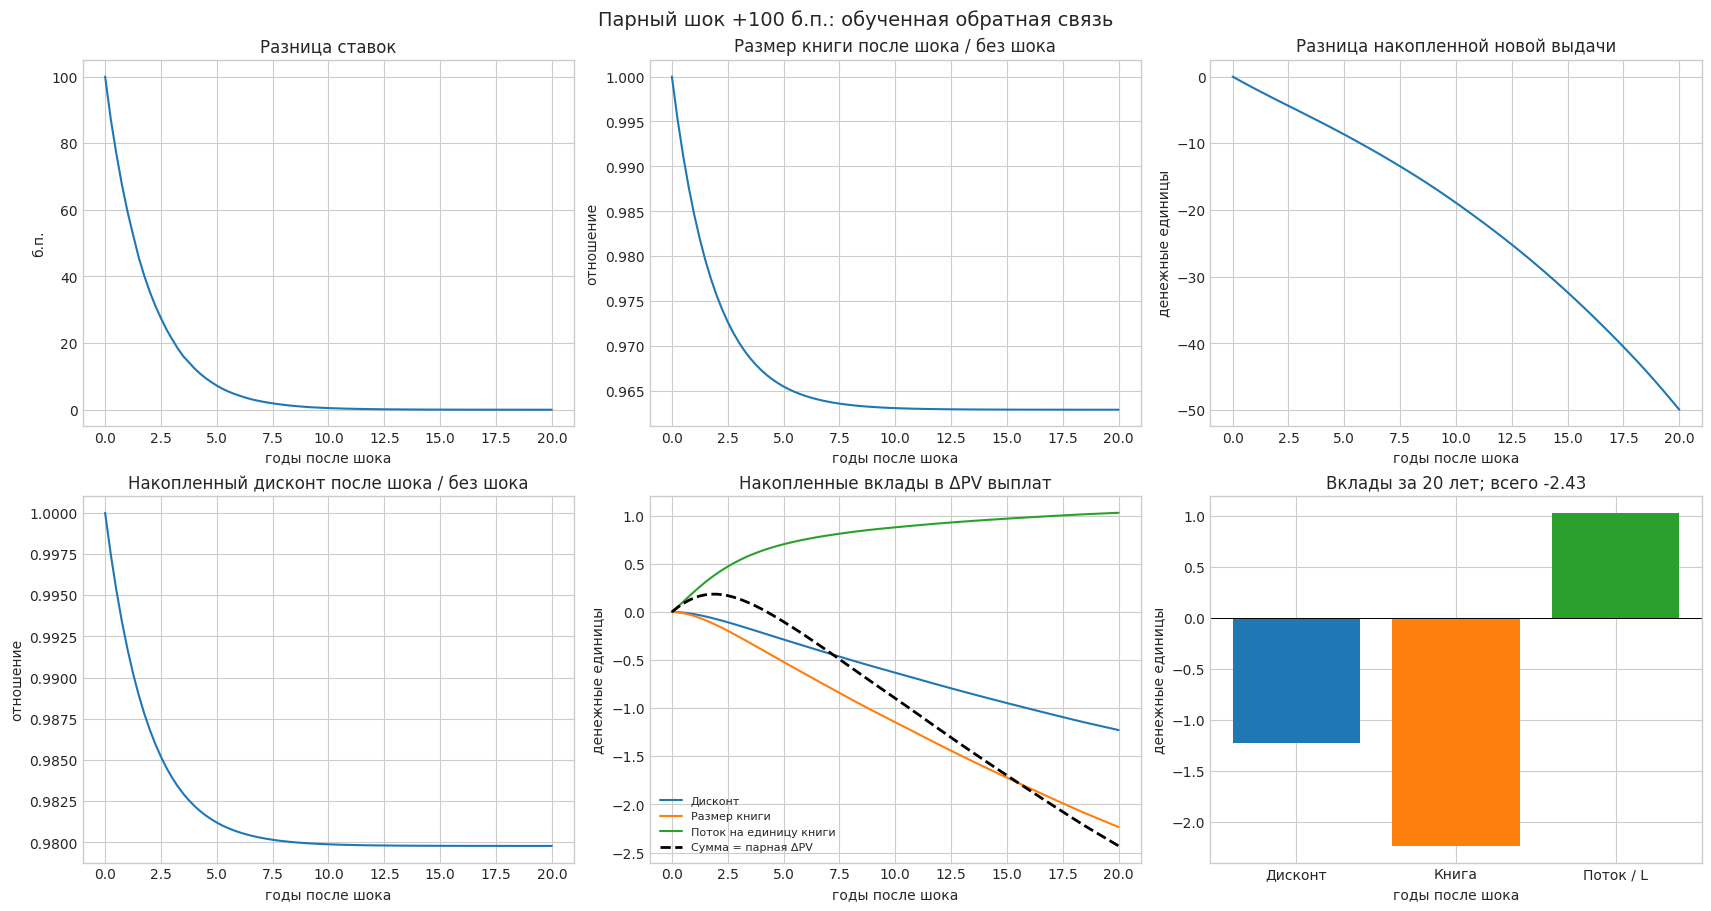

Парный шок +100 б.п.: обученная обратная связь; горизонт 20 лет: средняя парная ΔPV потоков -2.4314; дисконт -1.2272, размер книги -2.2351, поток на единицу книги +1.0309.
Это обрезанная риск-нейтральная стоимость потока, не бессрочная риск-чувствительная ΔV.


In [14]:
plot_paired_mechanisms(paired_mechanisms('learned'),
                       'Парный шок +100 б.п.: обученная обратная связь')

## Разложение $\Delta V$ без произвольной опорной политики

Обозначим через $MtM(x)$ рыночную стоимость **существующей** книги, через $\widehat V(x)$ выход сохранённой сети, а через $J_\gamma^{\widehat\pi}(x)$ — самостоятельно переоценённую бессрочную стоимость сохранённой обратной связи $\widehat\pi$ при энтропийной риск-чувствительности $\gamma$. Индекс $0$ означает оценку **той же** политики без риск-чувствительности. Новые выдачи и рост книги присутствуют в обоих $J$.

Для каждого состояния справедливо тождество

$$\widehat V=MtM+\underbrace{(J_0^{\widehat\pi}-MtM)}_{\text{продолжающаяся деятельность и разница правил оценки}}+\underbrace{(J_\gamma^{\widehat\pi}-J_0^{\widehat\pi})}_{\text{риск-чувствительность}}+\underbrace{(\widehat V-J_\gamma^{\widehat\pi})}_{\text{расхождение сети и оценки политики}}.$$

После вычитания значений до и после шока это даёт четыре вклада в $\Delta\widehat V$. Второй член включает будущую выдачу, рост книги, финансирование и различие оценочных мер $P/Q$; **он не является чистым эффектом управления**. Отдельного слагаемого для сравнения с политикой «всегда 50% fixed» теперь нет. Последний член — разность между выходом сети и отдельно оценённой политикой, а не сама невязка Беллмана. При несошедшихся оценках экономический смысл крупных компенсирующихся вкладов остаётся предварительным.

## Полногоризонтная оценка политик внутри ноутбука

Следующая ячейка для каждой из трёх пар «политика × риск-чувствительность» решает **уравнение оценки фиксированной политики**, без максимума по действиям. Используются один и тот же Bellman-шаг, нейросетевая архитектура и независимое контрольное облако; возле всех заданных сценариев добавляются локальные состояния. Оценка продолжается до заданной невязки либо до лимита итераций. На GPU полный прогон может занимать продолжительное время; результаты кешируются вместе с хешем чекпоинта и настроек.

По умолчанию ячейка **только загружает** сохранённые оценки: `TRAIN_MISSING_EVALUATIONS = False` в первой ячейке. Для первоначального обучения недостающих оценок установите `True`. Файлы `.pt` должны лежать в `risk_interpretation_cache/` рядом с чекпоинтом; сохранённые графики внутри `.ipynb` не содержат весов оценочных сетей. Ключ кеша учитывает чекпоинт, сценарии и настройки оценки.


In [15]:
anchors=torch.cat((scenario_states,
                   scenario_states+torch.tensor([SCENARIO_SHOCK,0,0,0],
                                                device=DEVICE,dtype=dtype)),dim=0)
from continuous_time_irrbb.risk_sensitive.stationary_solver import rescale_amounts

EVAL_CONFIG=replace(cfg,train_states=EVAL_TRAIN_STATES,
                    validation_states=EVAL_VALID_STATES,
                    iterations=EVAL_ITERATIONS,epochs_per_iteration=EVAL_EPOCHS,
                    target_batch=EVAL_BATCH,residual_tolerance=EVAL_TOLERANCE,
                    learning_rate=.0005)
settings={'evaluation_version':2,'checkpoint_sha256':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
          'scenarios':anchors.cpu().tolist(),'baseline_f':BASELINE_FIXED_SHARE,
          'policy_actions':POLICY_ACTIONS,'train_states':EVAL_TRAIN_STATES,
          'valid_states':EVAL_VALID_STATES,'iterations':EVAL_ITERATIONS,
          'epochs':EVAL_EPOCHS,'tolerance':EVAL_TOLERANCE,
          'batch':EVAL_BATCH,'seed':EVAL_SEED,'dtype':str(dtype),
          'learning_rate':EVAL_CONFIG.learning_rate,
          'exploration_steps':EVAL_CONFIG.exploration_steps}
cache_key=hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]
cache_dir=(Path('/private/tmp/irrbb_interpretation_smoke') if SMOKE
           else run_dir/'risk_interpretation_cache')
cache_dir.mkdir(parents=True,exist_ok=True)

required_pairs=(('half',0.),('learned',0.),
                ('learned',cfg.risk_aversion_per_loan))
previous_pairs=globals().get('pairs', {})
pairs={}
missing=[]
for policy,gamma in required_pairs:
    key=f'{policy}_gamma{gamma:g}_{cache_key}'
    cached=previous_pairs.get((policy,gamma))
    if cached is not None and cached.get('settings_hash')==cache_key:
        pairs[(policy,gamma)]=cached
        print('память:',key)
    else:
        cache_path=cache_dir/f'{key}.pt'
        if cache_path.exists():
            pairs[(policy,gamma)]=torch.load(cache_path,map_location='cpu',weights_only=True)
            print('кеш:',key)
        else:
            missing.append((policy,gamma,cache_path))
if missing and not TRAIN_MISSING_EVALUATIONS:
    files='\n'.join(str(item[2]) for item in missing)
    raise FileNotFoundError('Отсутствуют сохранённые оценки политик:\n'+files+
        '\nСкопируйте risk_interpretation_cache/ рядом с чекпоинтом '
        'или установите TRAIN_MISSING_EVALUATIONS=True.')
if missing:
    def scenario_cloud(n,seed,include_anchors=False):
        broad_n=n//2
        broad=generate_stationary_cloud(env,broad_n,seed,EVAL_CONFIG.exploration_steps,
                                        device=torch.device(DEVICE),dtype=dtype)
        gen=torch.Generator(device='cpu').manual_seed(seed+999)
        local_n=n-broad_n
        ids=torch.randint(len(anchors),(local_n,),generator=gen).to(DEVICE)
        noise=torch.randn((local_n,4),generator=gen,dtype=dtype).to(DEVICE)
        scale=torch.tensor([.012,.08*p.loans,.01*p.loans,.03*p.loans],
                           device=DEVICE,dtype=dtype)
        local=anchors[ids].clone()+noise*scale
        local[:,0].clamp_(min=0)
        local[:,1].clamp_(0,p.loans)
        local[:,2].clamp_(min=0)
        # Точные контрольные состояния обязательно присутствуют в обучении.
        if include_anchors and local_n>=len(anchors):local[:len(anchors)]=anchors
        return torch.cat((broad,local))

    train_x=scenario_cloud(EVAL_TRAIN_STATES,EVAL_SEED+1,include_anchors=True)
    valid_x=scenario_cloud(EVAL_VALID_STATES,EVAL_SEED+2)

    @torch.no_grad()
    def action_for(policy,states):
        if policy=='half':return torch.full(states.shape[:-1],BASELINE_FIXED_SHARE,
                                            device=DEVICE,dtype=dtype)
        if policy=='learned':
            return torch.cat([source_solution.action(part,action_count=POLICY_ACTIONS)
                              for part in states.split(EVAL_BATCH)])
        raise KeyError(policy)

    actions_by_policy={name:(action_for(name,train_x),action_for(name,valid_x),
                             action_for(name,anchors)) for name in ('half','learned')}

    @torch.no_grad()
    def policy_targets(operator,states,actions,continuation):
        return torch.cat([operator.evaluate(0,xb,ab,cfg.dt,continuation)
                          for xb,ab in zip(states.split(EVAL_BATCH),actions.split(EVAL_BATCH))])

    def evaluate_pair(policy,gamma_bar):
        key=f'{policy}_gamma{gamma_bar:g}_{cache_key}'
        cache_path=cache_dir/f'{key}.pt'
        if cache_path.exists():
            print('кеш:',key,flush=True)
            return torch.load(cache_path,map_location='cpu',weights_only=True)
        previous = globals().get('pairs', {}).get((policy,gamma_bar))
        if previous is not None and previous.get('settings_hash') == cache_key:
            print('память:',key,flush=True)
            return previous
        if not TRAIN_MISSING_EVALUATIONS:
            raise FileNotFoundError(
                f'Нет сохранённой оценки {cache_path}. Скопируйте папку '
                f'risk_interpretation_cache/ вместе с чекпоинтом или установите '
                f'TRAIN_MISSING_EVALUATIONS=True в первой ячейке для обучения.')
        torch.manual_seed(EVAL_SEED)
        train_a,valid_a,anchor_a=actions_by_policy[policy]
        config_gamma=replace(EVAL_CONFIG,risk_aversion_per_loan=gamma_bar)
        operator=make_operator(env,config_gamma,anchors)
        net=deepcopy(source_solution.value_net)
        stable=0
        diagnostics=[]
        converged=False
        for iteration in range(1,EVAL_ITERATIONS+1):
            cont=stationary_continuation(env,net)
            train_y=policy_targets(operator,train_x,train_a,cont)
            valid_y=policy_targets(operator,valid_x,valid_a,cont)
            new_net,fit=fit_projection(net,train_x,train_y,valid_x,valid_y,config_gamma)
            new_cont=stationary_continuation(env,new_net)
            with torch.no_grad():
                residual=new_net(valid_x)-policy_targets(operator,valid_x,valid_a,new_cont)
                anchor_target=operator.evaluate(0,anchors,anchor_a,cfg.dt,new_cont)
                anchor_residual=(new_net(anchors)-anchor_target).abs()
                anchor_change=(new_net(anchors)-net(anchors)).abs().max().item()
                info={'iteration':iteration,'bellman_rmse':residual.square().mean().sqrt().item(),
                      'bellman_q95_abs':torch.quantile(residual.abs(),.95).item(),
                      'anchor_max_abs':anchor_residual.max().item(),
                      'anchor_change':anchor_change,
                      'projection_rmse':fit['projection_rmse']}
            diagnostics.append(info)
            net=new_net
            good=(info['bellman_rmse']<=EVAL_TOLERANCE
                  and info['bellman_q95_abs']<=3*EVAL_TOLERANCE
                  and info['anchor_max_abs']<=EVAL_TOLERANCE
                  and info['anchor_change']<=EVAL_TOLERANCE)
            stable=stable+1 if good else 0
            if iteration==1 or iteration%50==0 or iteration==EVAL_ITERATIONS:
                print(f'{policy}, γ̄={gamma_bar:g}, iter={iteration}: '
                      f'RMSE={info["bellman_rmse"]:.5f}, '
                      f'anchor={info["anchor_max_abs"]:.5f}',flush=True)
            if stable>=5:
                converged=True
                break
        with torch.no_grad():anchor_values=net(anchors).cpu()
        result={'policy':policy,'gamma_bar':gamma_bar,
                'anchors':anchor_values,'converged':converged,
                'diagnostics':diagnostics,'settings_hash':cache_key}
        torch.save(result,cache_path)
        print('сохранено:',cache_path,flush=True)
        return result

    for policy,gamma,_ in missing:
        pairs[(policy,gamma)]=evaluate_pair(policy,gamma)
print('Статус оценок:')
for (policy,gamma),q in pairs.items():
    info=q['diagnostics'][-1]
    print(f'{policy:8s} γ̄={gamma:g}: converged={q["converged"]}, '
          f'RMSE={info["bellman_rmse"]:.5f}, '
          f'anchor={info["anchor_max_abs"]:.5f}, '
          f'drift={info["anchor_change"]:.5f}')


кеш: half_gamma0_e793404b1cd4fd99
кеш: learned_gamma0_e793404b1cd4fd99
кеш: learned_gamma10_e793404b1cd4fd99
Статус оценок:
half     γ̄=0: converged=False, RMSE=0.03111, anchor=0.06092, drift=0.00959
learned  γ̄=0: converged=False, RMSE=0.02645, anchor=0.04906, drift=0.01228
learned  γ̄=10: converged=False, RMSE=0.00825, anchor=0.00981, drift=0.00464


## Относительный шок для стратегии «всегда 50% fixed»

Здесь сравниваются $\Delta MtM/M(x)$ и $\Delta J_0^{\pi_{1/2}}/J_0^{\pi_{1/2}}(x)$. Вторая величина — чувствительность **риск-нейтральной** бессрочной стоимости фиксированной стратегии, полученной в ячейке оценки политик выше; это не выученная обратная связь и не риск-чувствительная оптимальная стоимость. Если оценка политики не сошлась, проценты тоже остаются численно предварительными.

Сценарий                              MtM до     J50 до    ΔMtM/M, %  ΔJ50/J50, %
Исходная книга: 50% fixed                 15.983   232.172      -3.66        -4.70
Низкая ставка, те же договоры             19.667   317.918      -3.23        -5.42
Высокая ставка, те же договоры            12.596   176.363      -4.27        -4.15
20% fixed в книге                         15.046   231.286      -1.66        -4.58
80% fixed в книге                         16.919   233.061      -5.43        -4.83
Низкая ставка + дорогой fixed             26.855   324.985      -3.90        -5.45
Пониженный капитал                        14.483   230.544      -4.04        -4.74
Вся книга — float (0% fixed)              14.422   230.672      -0.18        -4.49
Вся книга — fixed (100% fixed)            17.544   233.655      -6.51        -4.92


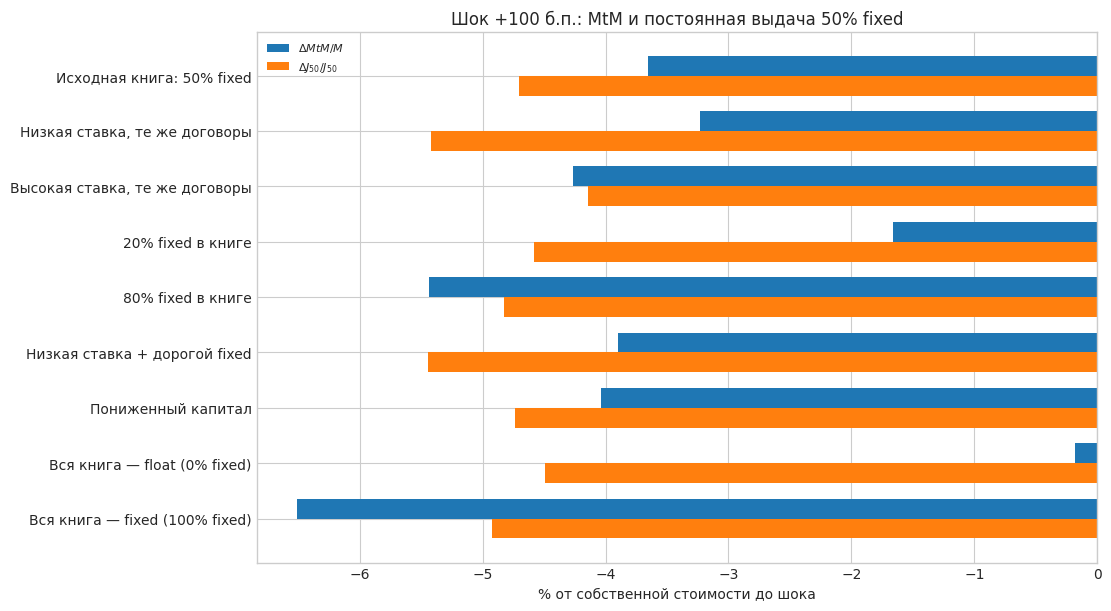

ВНИМАНИЕ: оценка J50 не сошлась; относительные показатели J50 предварительны.


In [16]:
baseline_eval=pairs[('half',0.)]
baseline_levels=baseline_eval['anchors'].detach().cpu().numpy()
n_scenarios=len(scenario_specs)
baseline_before=baseline_levels[:n_scenarios]
baseline_delta=baseline_levels[n_scenarios:]-baseline_before
with torch.no_grad():
    mtm_before_base=env.terminal_value(scenario_states).cpu().numpy()
mtm_delta_base=scenario_deltas[:,1]
safe_mtm=mtm_before_base>.01*L_SC
safe_baseline=baseline_before>.01*L_SC
mtm_relative=np.divide(100*mtm_delta_base,mtm_before_base,
                       out=np.full_like(mtm_before_base,np.nan),where=safe_mtm)
baseline_relative=np.divide(100*baseline_delta,baseline_before,
                            out=np.full_like(baseline_before,np.nan),where=safe_baseline)
labels=[row[0] for row in scenario_specs]
print('Сценарий                              MtM до     J50 до    ΔMtM/M, %  ΔJ50/J50, %')
for i,label in enumerate(labels):
    print(f'{label:38s} {mtm_before_base[i]:9.3f} {baseline_before[i]:9.3f} '
          f'{mtm_relative[i]:10.2f} {baseline_relative[i]:12.2f}')
fig,ax=plt.subplots(figsize=(11,6),constrained_layout=True)
y=np.arange(n_scenarios)
h=.36
ax.barh(y-h/2,mtm_relative,h,label=r'$\Delta MtM/M$',color='tab:blue')
ax.barh(y+h/2,baseline_relative,h,label=r'$\Delta J_{50}/J_{50}$',color='tab:orange')
ax.set(title='Шок +100 б.п.: MtM и постоянная выдача 50% fixed',
       xlabel='% от собственной стоимости до шока',yticks=y,yticklabels=labels)
ax.axvline(0,color='black',lw=.7)
ax.legend(fontsize=8)
ax.invert_yaxis()
plt.show()
if not baseline_eval['converged']:
    print('ВНИМАНИЕ: оценка J50 не сошлась; относительные показатели J50 предварительны.')

## Относительный шок для обученной политики

Те же сценарии, оси и нормировки, что на графике выше, но вместо $J_0^{\pi_{1/2}}$ показана риск-чувствительная стоимость $\widehat V$ сохранённой обученной политики. Разность графиков показывает влияние смены политики **и** риск-чувствительности; их нельзя отделить одним сравнением.


Сценарий                              MtM до шока  V до шока  ΔMtM/M, %  ΔV/V, %
Исходная книга: 50% fixed                  15.983     89.793      -3.66     -3.78
Низкая ставка, те же договоры              19.667    117.343      -3.23     -4.85
Высокая ставка, те же договоры             12.596     72.667      -4.27     -3.05
20% fixed в книге                          15.046     90.108      -1.66     -3.38
80% fixed в книге                          16.919     89.407      -5.43     -4.18
Низкая ставка + дорогой fixed              26.855    123.313      -3.90     -4.99
Пониженный капитал                         14.483     88.157      -4.04     -3.85
Вся книга — float (0% fixed)               14.422     90.244      -0.18     -3.11
Вся книга — fixed (100% fixed)             17.544     89.095      -6.51     -4.47


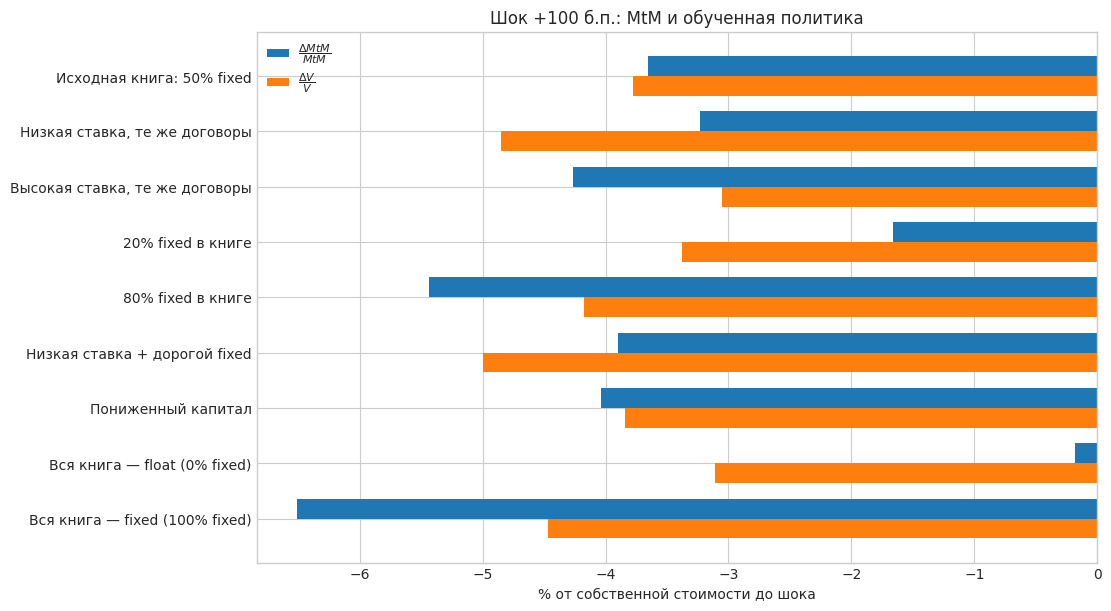

In [17]:
with torch.no_grad():
    mtm_before = env.terminal_value(scenario_states).cpu().numpy()
    value_before = source_solution.value(scenario_states).cpu().numpy()
shock_mtm = scenario_deltas[:, 1]
shock_value = scenario_deltas[:, 2]
min_denominator = 0.01*L_SC
relative_mtm = np.divide(100*shock_mtm,mtm_before,
                         out=np.full_like(mtm_before,np.nan),
                         where=mtm_before>min_denominator)
relative_value = np.divide(100*shock_value,value_before,
                           out=np.full_like(value_before,np.nan),
                           where=value_before>min_denominator)
labels = [row[0] for row in scenario_specs]
print('Сценарий                              MtM до шока  V до шока  ΔMtM/M, %  ΔV/V, %')
for i,label in enumerate(labels):
    print(f'{label:38s} {mtm_before[i]:10.3f} {value_before[i]:10.3f} '
          f'{relative_mtm[i]:10.2f} {relative_value[i]:9.2f}')
fig,ax=plt.subplots(figsize=(11,6),constrained_layout=True)
y=np.arange(len(labels))
h=.36
ax.barh(y-h/2,relative_mtm,h,label=r'$\dfrac{\Delta MtM}{MtM}$',color='tab:blue')
ax.barh(y+h/2,relative_value,h,label=r'$\dfrac{\Delta V}{V}$',color='tab:orange')
ax.set(title='Шок +100 б.п.: MtM и обученная политика',
       xlabel='% от собственной стоимости до шока',yticks=y,yticklabels=labels)
ax.axvline(0,color='black',lw=.7)
ax.legend(fontsize=8)
ax.invert_yaxis()
plt.show()

## Четыре вклада в $\Delta V$

График ниже использует сохранённые значения $MtM$, $J_0^{\widehat\pi}$, $J_\gamma^{\widehat\pi}$ и $\widehat V$. Сумма четырёх изменений точно равна $\Delta\widehat V$ для каждого сценария. Красный остаток — численное расхождение сети и переоценённой политики, а не экономический денежный поток. При отсутствии сходимости оценок политик отдельные вклады нельзя считать точно установленными.
Сохранённая ниже иллюстрация пересчитана из округлённой таблицы предыдущего прогона (4 знака); повторный запуск ячейки использует полные значения из кеша.


Сценарий                              MtM       деятельность      риск       остаток      ΔV
Исходная книга: 50% fixed                 -0.5844    -9.2164    +6.4157    -0.0050    -3.3901
Низкая ставка, те же договоры             -0.6360   -14.8261    +9.7693    +0.0060    -5.6869
Высокая ставка, те же договоры            -0.5374    -6.0134    +4.3305    +0.0012    -2.2191
20% fixed в книге                         -0.2495    -9.2315    +6.4425    -0.0055    -3.0439
80% fixed в книге                         -0.9193    -9.2026    +6.3908    -0.0045    -3.7356
Низкая ставка + дорогой fixed             -1.0462   -14.8794    +9.7279    +0.0388    -6.1590
Пониженный капитал                        -0.5844    -9.2091    +6.4065    -0.0031    -3.3901
Вся книга — float (0% fixed)              -0.0262    -9.2288    +6.4503    -0.0026    -2.8073
Вся книга — fixed (100% fixed)            -1.1426    -9.2048    +6.3800    -0.0121    -3.9795


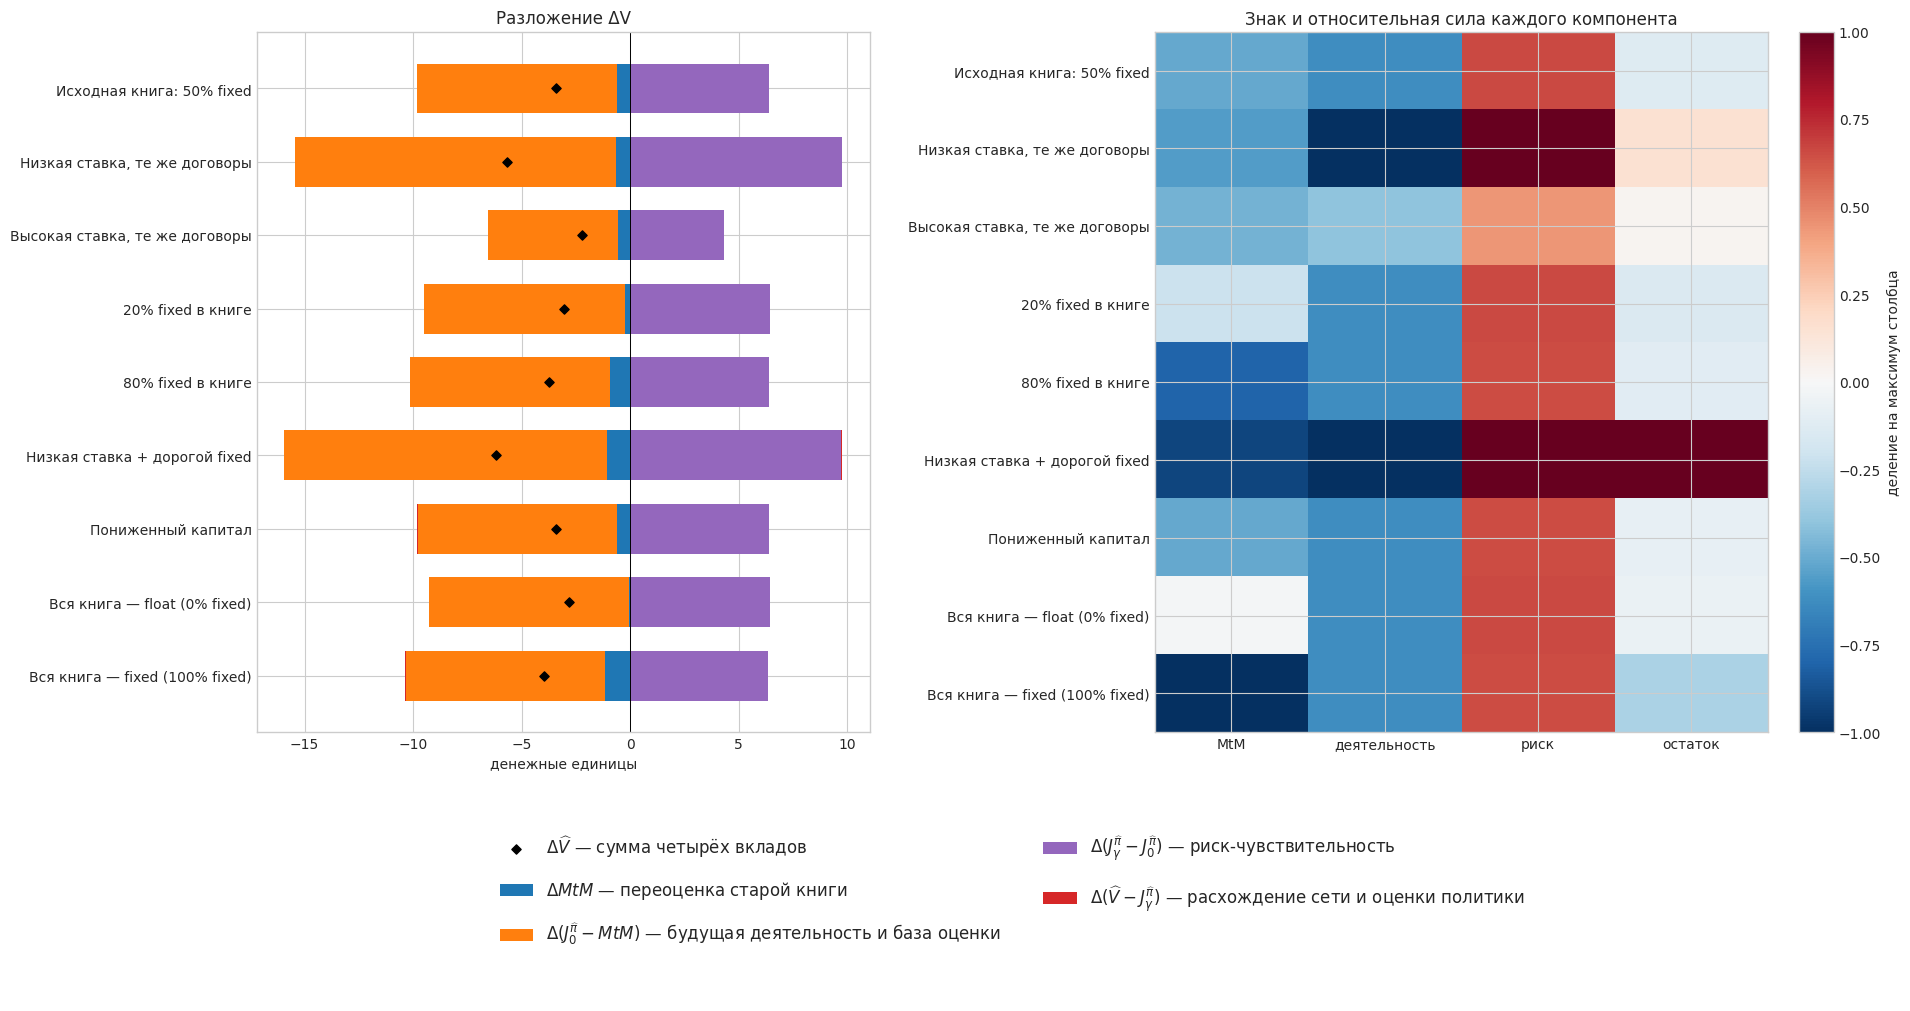

ВНИМАНИЕ: не все полногоризонтные оценки политик сошлись. Разложение алгебраически точно, но отдельные экономические вклады пока нельзя считать установленными численно.


In [18]:
scenario_labels=[spec[0] for spec in scenario_specs]
n=len(scenario_specs)
def values(policy,gamma):
    return pairs[(policy,gamma)]['anchors'].numpy()
def delta(v):return v[n:]-v[:n]
M1=env.terminal_value(anchors[n:]).detach().cpu().numpy()
MtM0=env.terminal_value(scenario_states).detach().cpu().numpy()
Mdelta=M1-MtM0
J0learn=values('learned',0.)
Jrisk=values('learned',cfg.risk_aversion_per_loan)
Vnet=np.concatenate((source_solution.value(scenario_states).detach().cpu().numpy(),
                     source_solution.value(anchors[n:]).detach().cpu().numpy()))
components=np.column_stack((
    Mdelta,
    delta(J0learn)-Mdelta,
    delta(Jrisk)-delta(J0learn),
    delta(Vnet)-delta(Jrisk),
))
component_names=[r'$\Delta MtM$ — переоценка старой книги',
                 r'$\Delta(J_0^{\widehat\pi}-MtM)$ — будущая деятельность и база оценки',
                 r'$\Delta(J_\gamma^{\widehat\pi}-J_0^{\widehat\pi})$ — риск-чувствительность',
                 r'$\Delta(\widehat V-J_\gamma^{\widehat\pi})$ — расхождение сети и оценки политики']
np.testing.assert_allclose(components.sum(1),scenario_deltas[:,2],atol=1e-4)
print('Сценарий                              MtM       деятельность      риск       остаток      ΔV')
for label,row,total in zip(scenario_labels,components,scenario_deltas[:,2]):
    print(f'{label:38s} '+' '.join(f'{v:+10.4f}' for v in row)+f' {total:+10.4f}')
fig=plt.figure(figsize=(19,10),layout='constrained')
grid=fig.add_gridspec(2,2,height_ratios=[7,2.2])
axes=[fig.add_subplot(grid[0,0]),fig.add_subplot(grid[0,1])]
legend_ax=fig.add_subplot(grid[1,:])
legend_ax.axis('off')
y=np.arange(n)
positive=np.zeros(n)
negative=np.zeros(n)
for j,(name,color) in enumerate(zip(component_names,
                                    ('tab:blue','tab:orange','tab:purple','tab:red'))):
    part=components[:,j]
    left=np.where(part>=0,positive,negative)
    axes[0].barh(y,part,left=left,label=name,color=color,height=.68)
    positive+=np.maximum(part,0)
    negative+=np.minimum(part,0)
axes[0].scatter(scenario_deltas[:,2],y,color='black',marker='D',s=22,
                zorder=5,label=r'$\Delta\widehat V$ — сумма четырёх вкладов')
axes[0].axvline(0,color='black',lw=.7)
axes[0].set(yticks=y,yticklabels=scenario_labels,xlabel='денежные единицы',
            title='Разложение ΔV')
axes[0].invert_yaxis()
handles,labels=axes[0].get_legend_handles_labels()
legend_ax.legend(handles,labels,loc='center',ncol=2,fontsize=12,
                 frameon=False,columnspacing=2.5,labelspacing=1.2,
                 handlelength=2.0)
scale=np.maximum(np.abs(components).max(axis=0),1e-9)
image=axes[1].imshow(components/scale,aspect='auto',cmap='RdBu_r',vmin=-1,vmax=1)
axes[1].set(yticks=y,yticklabels=scenario_labels,xticks=range(4),
            xticklabels=['MtM','деятельность','риск','остаток'],
            title='Знак и относительная сила каждого компонента')
fig.colorbar(image,ax=axes[1],label='деление на максимум столбца')
plt.show()
if any(not q['converged'] for q in pairs.values()):
    print('ВНИМАНИЕ: не все полногоризонтные оценки политик сошлись. '
          'Разложение алгебраически точно, но отдельные экономические вклады '
          'пока нельзя считать установленными численно.')


**Почему остаток нужен.** Сохранённая сеть аппроксимирует оптимальную функцию ценности, но её жадная политика может иметь другую самостоятельно переоценённую стоимость. Поэтому равенство «выход сети = стоимость выученной политики» не предполагается. Для чекпоинта с `converged=False` этот разрыв и невязки оценочных сетей особенно важны. В новом разложении нет отдельного вклада *оптимального управления*: чтобы измерить его, потребуется решить риск-нейтральную задачу $V^0$ и сравнить её с экономически определённым пассивным контрфактом.